<p class="lead">A prediction without an uncertainty is not a result, it is a number. This unit builds the three things a referee of a QSAR paper will ask for and a colleague about to spend money on a compound actually needs: an honest statement of <em>what the model cannot know</em> (aleatoric versus epistemic uncertainty, and the experimental error floor of the data itself), a definition of <em>where the model may be used</em> (the applicability domain, computed four ways and tested by how much accuracy degrades outside each), and an interval or prediction set with a <em>guaranteed</em> error rate (inductive conformal prediction, written here by hand in a dozen lines). The central experiment is the one that decides whether such guarantees survive contact with chemistry: the same conformal predictor calibrated and tested under a random split, and then under a scaffold split, where the exchangeability assumption that makes it valid no longer holds.</p>

<div class="box"><h4>Resumen en español</h4>
<p>Esta unidad trata la cuantificación de la incertidumbre. Se distingue la incertidumbre aleatoria de la epistémica y se mide el piso de error experimental a partir de las mediciones replicadas del propio conjunto de datos. Se definen y calculan cuatro dominios de aplicabilidad (caja delimitadora de descriptores, apalancamiento con el umbral h* y el gráfico de Williams, distancia de Tanimoto a los k vecinos más cercanos y densidad por núcleos) y se muestra cuánto se degrada la exactitud fuera de cada uno. Se construyen intervalos de predicción con la dispersión de un ensamble y con regresión cuantílica, verificando que su cobertura empírica es menor que la nominal, y luego se implementa a mano la predicción conformal inductiva, para regresión (simple y normalizada por dificultad) y para clasificación (conjuntos de predicción y la variante Mondrian condicionada por clase), comprobando la cobertura al 80, 90 y 95 por ciento bajo partición aleatoria y bajo partición por andamiaje. Se calibran probabilidades con Platt e isotónica y se cierra con los cinco principios de validación de la OCDE y un informe tipo QMRF.</p></div>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Distinguish aleatoric from epistemic uncertainty and explain why a point prediction without uncertainty is incomplete.</li>
<li>Define and compute an applicability domain (descriptor ranges, leverage and the Williams plot, distance to training set, density) and report how accuracy degrades outside it.</li>
<li>Obtain prediction intervals and class-probability sets from ensembles, quantile regression and inductive conformal prediction, and verify their empirical coverage.</li>
<li>Calibrate predicted probabilities (Platt, isotonic) and read a reliability diagram and a Brier score.</li>
<li>Comply with the OECD principles for QSAR model validation and fill a QMRF-style report for a model you fitted.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Run every cell; every number in the prose is printed above it. In Colab run <code>!pip install rdkit lightgbm</code> once before the setup cell. The model used throughout is refitted here in a few seconds. <a href="../U12_Validation/index.html">Unit 12</a> built the splits, <a href="../U14_Ensembles_Tuning/index.html">Unit 14</a> the ensemble, <a href="../U16_Interpretability/index.html">Unit 16</a> asked why a prediction came out as it did; this unit asks whether it should have been made at all, and <a href="../U19_Virtual_Screening/index.html">Unit 19</a> applies the answer to screening decisions.</p></div>

In [1]:
# Setup. In Google Colab run once:  !pip install rdkit lightgbm
from pathlib import Path
import urllib.request, time, math, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, rdkit, lightgbm as lgb
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator
RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore")
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})

REPO = "DanielBustosG/DanielBustosG.github.io"   # GitHub repository hosting this course (set once in common/config.json and here)
DATA_URL = f"https://raw.githubusercontent.com/{REPO}/main/DataScience/data/"
def data_path(name):
    '''Local ../data/<name> when the notebook runs from its course folder; otherwise (Colab) download once.'''
    local = Path("..") / "data" / name
    if local.exists():
        return local
    dest = Path("data") / name
    if not dest.exists():
        dest.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(DATA_URL + name, dest)
    return dest
def load_data(name, **kw):
    return pd.read_csv(data_path(name), **kw)

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| lightgbm", lgb.__version__, "| rdkit", rdkit.__version__)

numpy 2.4.6 | pandas 3.0.3 | scikit-learn 1.9.0 | lightgbm 4.6.0 | rdkit 2026.03.4


In [2]:
# Data, features and the two three-way splits (train / calibration / test).
df = load_data("rock1_chembl_curated.csv")
cmp_ = df.loc[~df["censored"]].reset_index(drop=True)
DESC = ["MolWt", "MolLogP", "TPSA", "HBD", "HBA", "RotB",
        "AromaticRings", "RingCount", "HeavyAtoms", "FractionCSP3", "QED"]
Xd = cmp_[DESC].to_numpy(dtype=float)
y = cmp_["pActivity"].to_numpy()
ycls = (y >= 7.0).astype(int)
scaf = cmp_["scaffold_smiles"].to_numpy()
mols = [Chem.MolFromSmiles(s) for s in cmp_["std_smiles"]]
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [gen.GetFingerprint(m) for m in mols]
Xfp = np.array([gen.GetFingerprintAsNumPy(m) for m in mols], dtype=np.float32)

def random_split(n, seed=0, fr=(0.6, 0.2)):
    p = np.random.default_rng(seed).permutation(n)
    a, b = int(fr[0]*n), int((fr[0]+fr[1])*n)
    return p[:a], p[a:b], p[b:]

def scaffold_split(scaffolds, fr=(0.6, 0.2)):
    '''Deterministic: the largest Bemis-Murcko families go to training, the rarest to test.'''
    groups = pd.Series(scaffolds).groupby(scaffolds).groups
    order = sorted(groups.values(), key=lambda g: (-len(g), str(scaffolds[g[0]])))
    tr, ca, te = [], [], []
    ntr, nca = int(fr[0]*len(scaffolds)), int(fr[1]*len(scaffolds))
    for g in order:
        (tr if len(tr) < ntr else ca if len(ca) < nca else te).extend(list(g))
    return np.array(tr), np.array(ca), np.array(te)

TR, CA, TE = random_split(len(y), seed=0)
TRs, CAs, TEs = scaffold_split(scaf)
print(f"compounds {len(y)}; potent (pActivity >= 7) {ycls.mean():.1%}")
print(f"random split    : train {len(TR)} / calibration {len(CA)} / test {len(TE)}")
print(f"scaffold split  : train {len(TRs)} / calibration {len(CAs)} / test {len(TEs)}; "
      f"scaffolds shared between train and test: "
      f"{len(set(scaf[TRs]) & set(scaf[TEs]))}")

compounds 2764; potent (pActivity >= 7) 33.1%
random split    : train 1658 / calibration 553 / test 553
scaffold split  : train 1658 / calibration 552 / test 554; scaffolds shared between train and test: 0


## 1. Two kinds of uncertainty, and the floor underneath both

A prediction can be uncertain for two different reasons<sup class="c"><a href="#r1">[1]</a></sup>.

**Aleatoric uncertainty** is noise in the world (or in the measurement of it) that no amount of extra data removes. For bioactivity data it is the irreducible scatter between two laboratories measuring the same compound in the same assay type: different cell batches, different ATP concentrations, different curve-fitting software. It is a property of the *target variable*.

**Epistemic uncertainty** is ignorance of the model: the compound is unlike anything in the training set, so the model is extrapolating. It *does* shrink with more (relevant) data, and it is the kind an applicability domain is designed to detect.

The two require different treatments and both set limits on what any model can achieve. The aleatoric part can be measured directly here, because our curated table keeps replicate information: 375 of the 2,764 exact-value compounds were measured more than once, with the spread of their measurements recorded.

In [3]:
# The experimental error floor, measured from the dataset's own replicates.
rep = cmp_.loc[cmp_["n_measurements"] > 1]
pooled_sd = math.sqrt(np.nansum((rep["n_measurements"] - 1) * rep["pActivity_sd"] ** 2)
                      / np.nansum(rep["n_measurements"] - 1))
print(f"compounds with replicate measurements: {len(rep)} of {len(cmp_)} "
      f"({rep['n_measurements'].sum():.0f} measurements in total)")
print(f"within-compound spread: median SD {rep['pActivity_sd'].median():.3f}, "
      f"mean SD {rep['pActivity_sd'].mean():.3f}, 90th percentile {rep['pActivity_sd'].quantile(0.9):.3f} log units")
print(f"pooled within-compound standard deviation sigma_exp = {pooled_sd:.3f} log units")
print(f"-> a perfect model predicting the true value of a single-measurement compound would still have "
      f"RMSE >= {pooled_sd:.3f}; comparing two independent measurements, {pooled_sd*math.sqrt(2):.3f}")
print(f"compounds flagged wide_spread (range > 1 log unit): {int(cmp_['wide_spread'].sum())}")
print(f"\nfor reference, the published estimate for heterogeneous public Ki data is about 0.54 log units "
      f"and for mixed IC50 data about 0.68 (references [2] and [3])")

compounds with replicate measurements: 375 of 2764 (993 measurements in total)
within-compound spread: median SD 0.000, mean SD 0.207, 90th percentile 0.757 log units
pooled within-compound standard deviation sigma_exp = 0.506 log units
-> a perfect model predicting the true value of a single-measurement compound would still have RMSE >= 0.506; comparing two independent measurements, 0.716
compounds flagged wide_spread (range > 1 log unit): 55

for reference, the published estimate for heterogeneous public Ki data is about 0.54 log units and for mixed IC50 data about 0.68 (references [2] and [3])


compounds whose replicate range exceeds 1 log unit: 55 of 375 (14.7% of replicated compounds)
median range 0.000, 90th percentile 1.379 log units


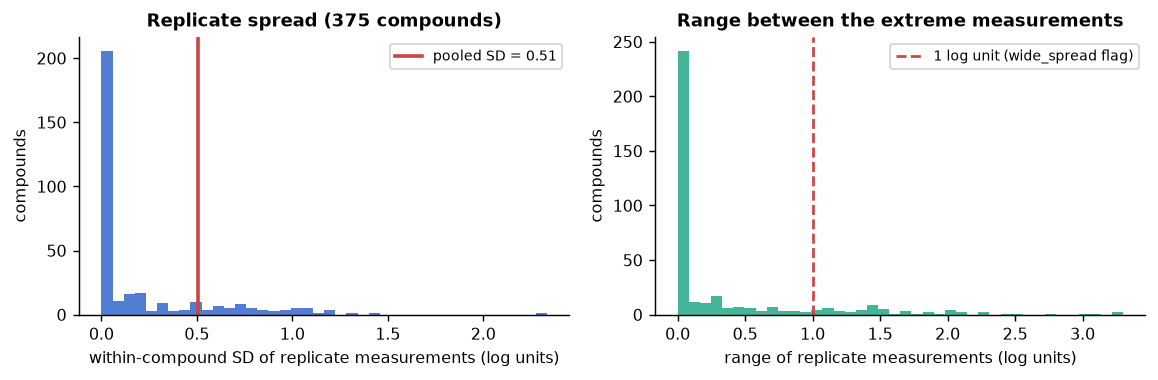

In [4]:
# Figure 1: the spread of replicate measurements, and what it implies for any model.
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.0))
axes[0].hist(rep["pActivity_sd"].dropna(), bins=40, color="#36c", alpha=.85)
axes[0].axvline(pooled_sd, color="#c44", lw=2, label=f"pooled SD = {pooled_sd:.2f}")
axes[0].set_xlabel("within-compound SD of replicate measurements (log units)")
axes[0].set_ylabel("compounds"); axes[0].legend(fontsize=7.5)
axes[0].set_title(f"Replicate spread ({len(rep)} compounds)")
axes[1].hist(rep["pActivity_range"].dropna(), bins=40, color="#2a8", alpha=.85)
axes[1].axvline(1.0, color="#c44", ls="--", lw=1.5, label="1 log unit (wide_spread flag)")
axes[1].set_xlabel("range of replicate measurements (log units)")
axes[1].set_ylabel("compounds"); axes[1].legend(fontsize=7.5)
axes[1].set_title("Range between the extreme measurements")
fig.tight_layout()
print(f"compounds whose replicate range exceeds 1 log unit: "
      f"{int((rep['pActivity_range'] > 1).sum())} of {len(rep)} "
      f"({100*(rep['pActivity_range'] > 1).mean():.1f}% of replicated compounds)")
print(f"median range {rep['pActivity_range'].median():.3f}, 90th percentile "
      f"{rep['pActivity_range'].quantile(0.9):.3f} log units")

<p class="caption"><b>Figure 1.</b> Left: the standard deviation of the replicate measurements of each multiply-measured compound, with the pooled estimate marked. Most compounds agree closely — the distribution is concentrated near zero — but a tail of compounds disagrees by a log unit or more between laboratories, and the pooled value is dominated by that tail. Right: the range between the extreme measurements of each compound; the dashed line is the 1-log-unit threshold the curated table uses for its wide_spread flag.</p>

A pooled within-compound standard deviation of roughly half a log unit is in line with the published analyses of public bioactivity data: Kramer and co-workers estimated about 0.54 log units for heterogeneous Ki values<sup class="c"><a href="#r2">[2]</a></sup> and Kalliokoski and co-workers about 0.68 for mixed IC50 data<sup class="c"><a href="#r3">[3]</a></sup>. **This is the floor.** A model whose test RMSE approaches 0.7 log units on such data is not mediocre; it is close to the measurement noise, and the remaining error cannot be removed by a better algorithm — only by better experiments. Reporting an RMSE without this comparison invites a reader to believe the model could be improved indefinitely.

<div class="box bridge"><h4>Domain context — what an IC50 is, and why two laboratories disagree</h4>
<p>An <strong>IC50</strong> is the concentration of compound at which an assay signal falls to half of its uninhibited value; a <strong>Ki</strong> is a thermodynamic binding constant derived from it; both are converted here to <strong>pActivity</strong> = -log10(molar concentration), so 7.0 means 100 nM and one unit is a tenfold change in potency. The value depends on the assay: for an ATP-competitive kinase inhibitor the measured IC50 shifts with the ATP concentration used, and functional (cell-based) assays give systematically different numbers from biochemical ones. ChEMBL records this provenance, and our curated table aggregated repeated measurements per compound while keeping their spread. Censored records ("&gt; 10 µM") were deliberately kept in the curated file and are excluded here, because a censored value is a different kind of uncertainty again — an interval, not a point.</p></div>

## 2. The model, its two splits, and where the error comes from

Everything below uses one model: a random forest<sup class="c"><a href="#r35">[35]</a></sup> on 2,048-bit Morgan fingerprints of the curated ChEMBL table<sup class="c"><a href="#r34">[34]</a></sup>, refitted inside this notebook. Two splits are used throughout: a random split, and a deterministic Bemis-Murcko scaffold split<sup class="c"><a href="#r33">[33]</a></sup> in which no scaffold family appears on both sides — the standard stress test for "would this model work on a new chemotype"<sup class="c"><a href="#r31">[31]</a><a href="#r32">[32]</a></sup>. Each split has three parts: **training** (fit the model), **calibration** (fit the uncertainty) and **test** (measure whether the uncertainty was right). The calibration part is what makes conformal prediction possible and is the piece most pipelines forget.

In [5]:
# One model, two splits: accuracy, and the distance from test compounds to the training set.
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

def fit_rf(tr):
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=0).fit(Xfp[tr], y[tr])

def knn_distance(query_idx, train_idx, k=5):
    '''Mean Tanimoto distance from each query compound to its k nearest training compounds.'''
    out = np.empty(len(query_idx))
    train_fps = [fps[j] for j in train_idx]
    for a, i in enumerate(query_idx):
        s = np.array(DataStructs.BulkTanimotoSimilarity(fps[i], train_fps))
        out[a] = 1.0 - np.sort(s)[::-1][:k].mean()
    return out

models, info = {}, []
for name, (tr, ca, te) in {"random": (TR, CA, TE), "scaffold": (TRs, CAs, TEs)}.items():
    m = fit_rf(tr); models[name] = m
    pred = m.predict(Xfp[te])
    d = knn_distance(te, tr)
    info.append({"split": name, "n_train": len(tr), "n_test": len(te),
                 "R2": r2_score(y[te], pred), "MAE": mean_absolute_error(y[te], pred),
                 "RMSE": float(np.sqrt(((y[te] - pred) ** 2).mean())),
                 "median kNN(5) Tanimoto distance": float(np.median(d))})
info = pd.DataFrame(info)
print(info.round(3).to_string(index=False))
print(f"\nexperimental floor sigma_exp = {pooled_sd:.3f}; the random-split RMSE is "
      f"{info.loc[0, 'RMSE'] / pooled_sd:.2f} times it, the scaffold-split RMSE "
      f"{info.loc[1, 'RMSE'] / pooled_sd:.2f} times it")

   split  n_train  n_test    R2   MAE  RMSE  median kNN(5) Tanimoto distance
  random     1658     553 0.504 0.572 0.769                            0.352
scaffold     1658     554 0.197 0.716 0.927                            0.511

experimental floor sigma_exp = 0.506; the random-split RMSE is 1.52 times it, the scaffold-split RMSE 1.83 times it


The two splits differ in exactly the way Unit 12 predicted, and the distance column explains why: under a scaffold split the median test compound is much further from the training set in fingerprint space, and the error grows accordingly. The random-split RMSE sits at a small multiple of the experimental floor; most of the remaining error is epistemic and is concentrated in the compounds the model has never seen the like of. Quantifying *that* is the applicability domain.

## 3. The applicability domain, four ways

The OECD guidance makes "a defined domain of applicability" the third of its five validation principles, without prescribing a method; the literature offers a dozen<sup class="c"><a href="#r4">[4]</a><a href="#r5">[5]</a></sup>. Four are computed below, in increasing order of usefulness for a fingerprint model.

**(a) Bounding box (descriptor ranges).** A compound is inside if every descriptor lies within the training minimum and maximum. Crude, and generous: a molecule can satisfy all eleven ranges separately while occupying a region none of the training compounds inhabit.

**(b) Leverage and the Williams plot.** For a linear model with design matrix $\mathbf{X}$, the leverage of a query point is $h_i = \mathbf{x}_i^{\top}(\mathbf{X}^{\top}\mathbf{X})^{-1}\mathbf{x}_i$, the diagonal of the hat matrix: a measure of how far it sits from the centre of the training data in the metric the model actually uses. The conventional warning threshold is $h^{*} = 3p/n$ ($p$ parameters, $n$ training rows), and the **Williams plot** of standardised residual against leverage is the classical QSAR diagnostic: the top-right quadrant holds influential outliers<sup class="c"><a href="#r6">[6]</a><a href="#r7">[7]</a></sup>.

**(c) Distance to the training set.** The mean Tanimoto distance to the $k$ nearest training compounds, in the same fingerprint space the model uses<sup class="c"><a href="#r8">[8]</a></sup>.

**(d) Density.** A kernel density estimate of the training distribution (here in the first five principal components of the standardised descriptors); a compound in a low-density region is an extrapolation even if it is inside the bounding box.

A domain definition is only worth reporting if accuracy actually degrades outside it, so each is scored that way.

In [6]:
# (a) bounding box, (c) kNN distance and (d) kernel density, for the random-split fingerprint model.
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KernelDensity
from scipy.stats import spearmanr

m_rand = models["random"]
pred_te = m_rand.predict(Xfp[TE]); err = np.abs(y[TE] - pred_te)
sc = StandardScaler().fit(Xd[TR]); Ztr, Zte = sc.transform(Xd[TR]), sc.transform(Xd[TE])

lo, hi = Xd[TR].min(0), Xd[TR].max(0)
in_box = np.all((Xd[TE] >= lo) & (Xd[TE] <= hi), axis=1)

d_knn = knn_distance(TE, TR, k=5)
thr_knn = np.quantile(knn_distance(CA, TR, k=5), 0.90)         # threshold set on the calibration set

pca = PCA(n_components=5, random_state=0).fit(Ztr)
kde = KernelDensity(bandwidth=0.8).fit(pca.transform(Ztr))
dens_te = kde.score_samples(pca.transform(Zte))
thr_dens = np.quantile(kde.score_samples(pca.transform(Ztr)), 0.05)

rows = []
for name, inside in [("bounding box (descriptors)", in_box),
                     (f"kNN(5) Tanimoto distance < {thr_knn:.2f}", d_knn < thr_knn),
                     ("kernel density above 5th pct", dens_te >= thr_dens)]:
    rows.append({"AD definition": name, "% inside": 100 * inside.mean(),
                 "MAE inside": err[inside].mean() if inside.any() else np.nan,
                 "MAE outside": err[~inside].mean() if (~inside).any() else np.nan,
                 "RMSE inside": float(np.sqrt((err[inside] ** 2).mean())) if inside.any() else np.nan,
                 "RMSE outside": float(np.sqrt((err[~inside] ** 2).mean())) if (~inside).any() else np.nan})
ad = pd.DataFrame(rows)
print(ad.round(3).to_string(index=False))
print(f"\nSpearman correlation with the absolute error:  kNN distance {spearmanr(err, d_knn).statistic:+.3f}   "
      f"negative log-density {spearmanr(err, -dens_te).statistic:+.3f}")

                  AD definition  % inside  MAE inside  MAE outside  RMSE inside  RMSE outside
     bounding box (descriptors)    99.277       0.574        0.307        0.771         0.435
kNN(5) Tanimoto distance < 0.58    88.427       0.566        0.620        0.769         0.770
   kernel density above 5th pct    92.948       0.571        0.582        0.769         0.769

Spearman correlation with the absolute error:  kNN distance +0.142   negative log-density -0.036


In [7]:
# Error against distance-to-training, in quartiles - the degradation curve that matters.
qt = pd.qcut(d_knn, 4, labels=["Q1 nearest", "Q2", "Q3", "Q4 farthest"])
deg = pd.DataFrame({"distance": d_knn, "abs_error": err, "quartile": qt}) \
        .groupby("quartile", observed=True) \
        .agg(n=("abs_error", "size"), mean_distance=("distance", "mean"),
             MAE=("abs_error", "mean"), RMSE=("abs_error", lambda e: float(np.sqrt((e ** 2).mean()))),
             frac_error_gt_1=("abs_error", lambda e: float((e > 1.0).mean())))
print(deg.round(3).to_string())
print(f"\nMAE rises from {deg['MAE'].iloc[0]:.3f} in the nearest quartile to {deg['MAE'].iloc[-1]:.3f} "
      f"in the farthest ({100*(deg['MAE'].iloc[-1]/deg['MAE'].iloc[0] - 1):.0f}% worse); "
      f"the share of errors above 1 log unit goes from {deg['frac_error_gt_1'].iloc[0]:.1%} "
      f"to {deg['frac_error_gt_1'].iloc[-1]:.1%}")

               n  mean_distance    MAE   RMSE  frac_error_gt_1
quartile                                                      
Q1 nearest   139          0.211  0.498  0.736            0.144
Q2           138          0.307  0.589  0.803            0.181
Q3           138          0.395  0.554  0.719            0.152
Q4 farthest  138          0.594  0.647  0.814            0.217

MAE rises from 0.498 in the nearest quartile to 0.647 in the farthest (30% worse); the share of errors above 1 log unit goes from 14.4% to 21.7%


In [8]:
# (b) Leverage and the Williams plot, for a descriptor-based linear model (where leverage is defined).
from sklearn.linear_model import RidgeCV
ridge = RidgeCV(alphas=np.logspace(-2, 3, 20)).fit(Ztr, y[TR])
res = y[TE] - ridge.predict(Zte)
std_res = res / res.std()
Xmat = np.column_stack([np.ones(len(Ztr)), Ztr])
Hinv = np.linalg.inv(Xmat.T @ Xmat)
Xq = np.column_stack([np.ones(len(Zte)), Zte])
lev = np.einsum("ij,jk,ik->i", Xq, Hinv, Xq)
p_param = Xmat.shape[1]
h_star = 3 * p_param / len(Ztr)
out_lev = lev > h_star
print(f"ridge model on {p_param - 1} descriptors, n_train = {len(Ztr)}  ->  h* = 3p/n = {h_star:.4f}")
print(f"test compounds with leverage above h*: {out_lev.sum()} ({100*out_lev.mean():.1f}%)")
print(f"MAE inside the leverage domain {np.abs(res[~out_lev]).mean():.3f}, outside {np.abs(res[out_lev]).mean():.3f}")
print(f"standardised residuals beyond +-3: {int((np.abs(std_res) > 3).sum())} compounds "
      f"({100*(np.abs(std_res) > 3).mean():.1f}%)")
print(f"compounds in the top-right quadrant (|std residual| > 3 and h > h*): "
      f"{int(((np.abs(std_res) > 3) & out_lev).sum())}")

ridge model on 11 descriptors, n_train = 1658  ->  h* = 3p/n = 0.0217
test compounds with leverage above h*: 11 (2.0%)
MAE inside the leverage domain 0.791, outside 1.336
standardised residuals beyond +-3: 1 compounds (0.2%)
compounds in the top-right quadrant (|std residual| > 3 and h > h*): 1


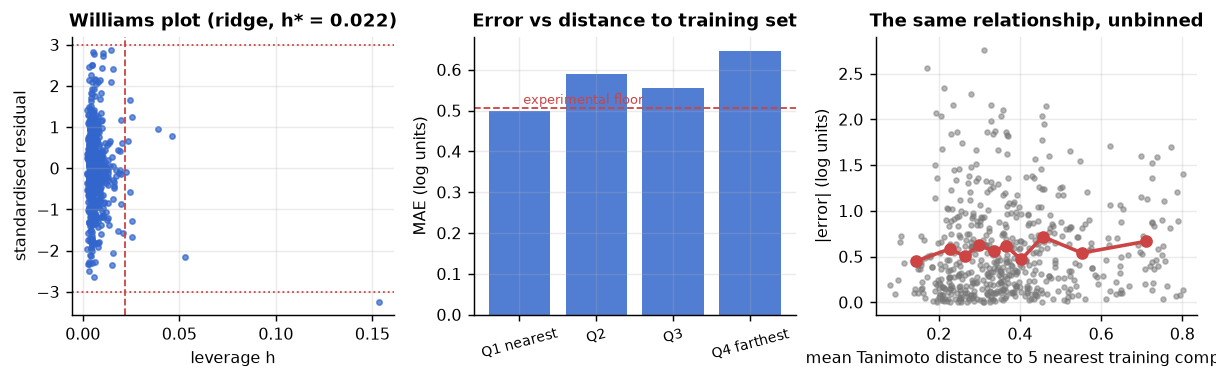

In [9]:
# Figure 2: the Williams plot and the two degradation curves.
fig, axes = plt.subplots(1, 3, figsize=(9.4, 3.0))
axes[0].scatter(lev, std_res, s=8, color="#36c", alpha=.7)
axes[0].axvline(h_star, color="#c44", ls="--", lw=1)
axes[0].axhline(3, color="#c44", ls=":", lw=1); axes[0].axhline(-3, color="#c44", ls=":", lw=1)
axes[0].set_xlabel("leverage h"); axes[0].set_ylabel("standardised residual")
axes[0].set_title(f"Williams plot (ridge, h* = {h_star:.3f})")
axes[1].bar(range(4), deg["MAE"], color="#36c", alpha=.85)
axes[1].errorbar(range(4), deg["MAE"], fmt="none")
axes[1].set_xticks(range(4)); axes[1].set_xticklabels(deg.index, fontsize=7.5, rotation=15)
axes[1].set_ylabel("MAE (log units)"); axes[1].set_title("Error vs distance to training set")
axes[1].axhline(pooled_sd, color="#c44", ls="--", lw=1)
axes[1].text(0.05, pooled_sd * 1.02, "experimental floor", fontsize=7, color="#c44")
axes[2].scatter(d_knn, err, s=7, alpha=.5, color="#777")
bins = np.quantile(d_knn, np.linspace(0, 1, 11))
cent = (bins[:-1] + bins[1:]) / 2
binned = [err[(d_knn >= bins[i]) & (d_knn < bins[i+1])].mean() for i in range(10)]
axes[2].plot(cent, binned, "o-", color="#c44", lw=2)
axes[2].set_xlabel("mean Tanimoto distance to 5 nearest training compounds")
axes[2].set_ylabel("|error| (log units)"); axes[2].set_title("The same relationship, unbinned")
for a in axes: a.grid(alpha=.25)
fig.tight_layout()

<p class="caption"><b>Figure 2.</b> Left: Williams plot for the descriptor ridge model — leverage against standardised residual, with the h* threshold (dashed) and the ±3 residual lines (dotted); the printed counts give the occupancy of the top-right quadrant. Centre: mean absolute error of the fingerprint model by quartile of distance to the training set, with the experimental error floor marked. Right: the same data unbinned, with a decile-averaged trend; the cloud is wide at every distance, so the relationship is a shift of the mean, not a threshold.</p>

The table and the figure together give an uncomfortable but useful result.

- The **descriptor bounding box** declares almost every test compound to be inside, and the few outside it are not predicted worse. As an applicability domain for a fingerprint model it is useless: it is measured in the wrong space.
- **Leverage** behaves exactly as the QSAR literature says — *for the model it is defined for*. For the ridge model, the compounds beyond $h^{*}$ are predicted markedly worse. It says nothing about the random forest, whose geometry is not that of a linear model in descriptor space.
- **kNN Tanimoto distance** is the only definition here that tracks the fingerprint model's error at all: the mean absolute error rises from about 0.50 in the nearest quartile to about 0.65 in the farthest (with a non-monotone middle pair, the quartiles being only 138 compounds each) and the share of errors above one log unit rises by about half. The effect is real and modest.
- **Kernel density** in descriptor-PCA space adds little once distance is known, because it measures the same thing more crudely.

### 3.1 Retention curves: the operational form of an applicability domain

A project does not ask "is this compound inside the domain" but "if I only trust the most reliable half of my predictions, how good are they?". The answer is a **retention curve**: sort the test set by an uncertainty proxy, keep the most reliable fraction, and plot the error of what is kept.

The general rule: **define the applicability domain in the space the model computes in, and prove it by showing the degradation.** An AD stated without a degradation table is decoration. Note also what the right-hand panel shows: even in the nearest quartile some compounds are predicted badly (activity cliffs), so distance bounds the *average* error, not the individual one. That is what conformal prediction is for.

<div class="exercise"><h4>Exercise 1</h4>
<p>Recompute the kNN-distance degradation table for the <em>scaffold</em>-split model, using its own training set as the reference. Compare the four quartile means with those of the random split and explain why the nearest quartile of a scaffold split is already as distant as the third quartile of a random split.</p></div>

                    proxy  RMSE of the best 50%  RMSE of all
 kNN(5) Tanimoto distance                 0.771        0.769
  negative kernel density                 0.823        0.769
ensemble spread (tree SD)                 0.620        0.769
   random order (control)                 0.789        0.769


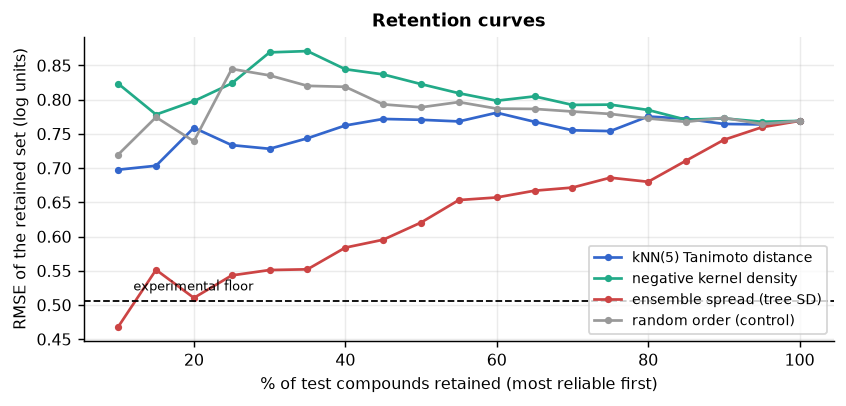

In [10]:
# Figure 3: retention curves - error of the retained fraction, ranked by three uncertainty proxies.
sd_te_full = np.stack([t.predict(Xfp[TE]) for t in m_rand.estimators_]).std(0)
proxies = {"kNN(5) Tanimoto distance": d_knn, "negative kernel density": -dens_te,
           "ensemble spread (tree SD)": sd_te_full, "random order (control)":
           np.random.default_rng(3).normal(size=len(TE))}
fracs = np.linspace(0.1, 1.0, 19)
fig, ax = plt.subplots(figsize=(6.6, 3.2))
summary_rows = []
for (name, pr), colr in zip(proxies.items(), ["#36c", "#2a8", "#c44", "#999"]):
    order = np.argsort(pr)
    curve = [float(np.sqrt((err[order[:max(int(f*len(TE)), 10)]] ** 2).mean())) for f in fracs]
    ax.plot(100 * fracs, curve, "o-", ms=3, color=colr, label=name)
    summary_rows.append({"proxy": name, "RMSE of the best 50%": curve[8], "RMSE of all": curve[-1]})
ax.axhline(pooled_sd, color="k", ls="--", lw=1)
ax.text(12, pooled_sd * 1.03, "experimental floor", fontsize=7)
ax.set_xlabel("% of test compounds retained (most reliable first)")
ax.set_ylabel("RMSE of the retained set (log units)")
ax.set_title("Retention curves"); ax.legend(fontsize=7.5); ax.grid(alpha=.25)
fig.tight_layout()
print(pd.DataFrame(summary_rows).round(3).to_string(index=False))

<p class="caption"><b>Figure 3.</b> RMSE of the retained subset as a function of how much of the test set is kept, ranking compounds by three uncertainty proxies and by a random order as control. A useful proxy bends the curve downwards on the left; the random control is flat by construction. The printed table gives the RMSE of the most reliable half under each ranking.</p>

This figure corrects an impression the quartile table could leave. Ranking by **distance to the training set** barely improves the retained RMSE at all — the most reliable half by that criterion is no better than a random half — whereas ranking by **ensemble spread** cuts the RMSE of the retained half substantially. The two measurements are consistent: distance shifts the *average* error by a modest amount, but the RMSE is dominated by a minority of large errors (activity cliffs, mis-annotated records) that are not especially distant from the training set. The operational conclusion is uncomfortable for the classical applicability-domain literature and important for practice: **for per-compound triage, a model-internal difficulty estimate beats a chemical-distance domain**, while the distance remains the right thing to report as a domain definition because it is computable for compounds that have never been measured. Use both — distance to declare the domain, ensemble spread (normalised by conformal calibration, Section 5) to rank inside it.

## 4. Heuristic intervals, and why they do not cover

Two intervals are routinely reported without being checked.

**Ensemble spread.** A random forest gives a prediction per tree; the standard deviation across trees is often quoted as an uncertainty, and $\hat y \pm 1.645\,s$ as a 90 % interval<sup class="c"><a href="#r25">[25]</a></sup>. The hidden assumption is that the tree-to-tree spread equals the error distribution, which it does not: it measures disagreement among correlated models trained on the same data, not the irreducible noise.

**Quantile regression.** Fit two models with the pinball loss<sup class="c"><a href="#r24">[24]</a></sup> at the 5th and 95th percentiles and use them as interval endpoints. This at least targets quantiles of the conditional distribution, but the quantiles are estimated — with their own bias and over-fitting — and nothing guarantees that 90 % of future observations will fall inside.

Both are tested below the only way that counts: by **empirical coverage**, the fraction of held-out compounds whose true value lies in the interval.

In [11]:
# Ensemble-spread intervals and quantile-regression intervals: coverage and width.
P_trees = np.stack([t.predict(Xfp[TE]) for t in m_rand.estimators_])
sd_trees = P_trees.std(0)
cov_rf = float(np.mean(np.abs(y[TE] - pred_te) <= 1.645 * sd_trees))
q_lo = lgb.LGBMRegressor(objective="quantile", alpha=0.05, n_estimators=300,
                         random_state=0, verbose=-1).fit(Xfp[TR], y[TR])
q_hi = lgb.LGBMRegressor(objective="quantile", alpha=0.95, n_estimators=300,
                         random_state=0, verbose=-1).fit(Xfp[TR], y[TR])
lo_q, hi_q = q_lo.predict(Xfp[TE]), q_hi.predict(Xfp[TE])
cov_q = float(np.mean((y[TE] >= lo_q) & (y[TE] <= hi_q)))
print(f"random forest +- 1.645 SD across trees : coverage {cov_rf:.3f} (nominal 0.90), "
      f"mean width {np.mean(2*1.645*sd_trees):.3f} log units")
print(f"quantile gradient boosting, 5th-95th   : coverage {cov_q:.3f} (nominal 0.90), "
      f"mean width {np.mean(hi_q - lo_q):.3f} log units")
print(f"\ntree-to-tree SD ranges {sd_trees.min():.2f}-{sd_trees.max():.2f} and correlates with the "
      f"absolute error at Spearman {spearmanr(np.abs(y[TE] - pred_te), sd_trees).statistic:+.3f}")
print("-> the ensemble spread ranks uncertainty usefully but its scale is wrong; both intervals under-cover")

  File "/usr/lib/python3.11/site-packages/joblib/externals/loky/backend/context.py", line 249, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.11/site-packages/joblib/externals/loky/backend/context.py", line 318, in _count_physical_cores_darwin
    return int(cpu_info)
           ^^^^^^^^^^^^^
random forest +- 1.645 SD across trees : coverage 0.857 (nominal 0.90), mean width 2.186 log units
quantile gradient boosting, 5th-95th   : coverage 0.752 (nominal 0.90), mean width 1.824 log units

tree-to-tree SD ranges 0.16-1.40 and correlates with the absolute error at Spearman +0.346
-> the ensemble spread ranks uncertainty usefully but its scale is wrong; both intervals under-cover


Both heuristics under-cover: at a nominal 90 % they contain the truth for substantially fewer than nine compounds in ten. Notice the second printed statistic, though — the tree-to-tree spread *ranks* compounds by difficulty with a clear positive correlation to the actual error. That combination (useful ranking, wrong scale) is exactly what conformal prediction turns into a guarantee.

## 5. Inductive conformal prediction, written by hand

The recipe<sup class="c"><a href="#r11">[11]</a><a href="#r12">[12]</a></sup> has three steps and no model assumptions.

1. **Fit** the model on the training set (the *proper training set*).
2. **Calibrate**: on a held-out calibration set of size $n$, compute a *nonconformity score* for every compound — for regression, the absolute residual $\alpha_i = |y_i - \hat y_i|$.
3. **Predict**: for a confidence level $1-\varepsilon$, take the $k$-th smallest calibration score with
$$ k = \left\lceil (n+1)(1-\varepsilon) \right\rceil, $$
and output the interval $\hat y \pm \alpha_{(k)}$.

The guarantee is distribution-free: **if the calibration and test compounds are exchangeable, the interval contains the truth with probability at least $1-\varepsilon$.** The proof is a rank argument in one line — under exchangeability, the rank of a new compound's nonconformity score among the $n+1$ scores is uniform, so the probability that it exceeds the $k$-th smallest is at most $\varepsilon$. Everything about the model — bias, over-fitting, the shape of the residuals — is absorbed by the calibration scores.

### 5.1 Worked example by hand

Suppose a calibration set of $n = 9$ compounds with absolute residuals, sorted:

| rank $i$ | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| $\alpha_{(i)}$ | 0.05 | 0.11 | 0.18 | 0.26 | 0.33 | 0.47 | 0.52 | 0.80 | 1.40 |

For $\varepsilon = 0.2$ (80 % confidence): $k = \lceil 10 \times 0.8 \rceil = 8$, so the half-width is $\alpha_{(8)} = 0.80$. For $\varepsilon = 0.1$: $k = \lceil 10 \times 0.9 \rceil = 9$, half-width $1.40$ — the largest calibration residual. For $\varepsilon = 0.05$: $k = \lceil 10 \times 0.95 \rceil = 10 > n$, and **no finite interval can be issued** from nine calibration points. That last line is the practical lesson: the calibration set must satisfy $n \ge 1/\varepsilon - 1$, so 95 % confidence needs at least 19 calibration compounds and a stable estimate needs hundreds.

In [12]:
# The worked example, confirmed; then the same function applied to the real calibration set.
def conformal_quantile(scores, eps):
    '''k-th smallest nonconformity score with k = ceil((n+1)(1-eps)); None if k > n.'''
    s = np.sort(np.asarray(scores)); n = len(s)
    k = math.ceil((n + 1) * (1 - eps))
    return None if k > n else float(s[k - 1])

demo = [0.05, 0.11, 0.18, 0.26, 0.33, 0.47, 0.52, 0.80, 1.40]
for eps in [0.2, 0.1, 0.05]:
    k = math.ceil((len(demo) + 1) * (1 - eps))
    q = conformal_quantile(demo, eps)
    print(f"eps = {eps:.2f}: k = ceil(10 x {1-eps:.2f}) = {k}  ->  "
          + (f"half-width alpha_({k}) = {q:.2f}" if q is not None else "k > n, no finite interval"))
print(f"\nminimum calibration size for 95% confidence: n >= {math.ceil(1/0.05) - 1}")

eps = 0.20: k = ceil(10 x 0.80) = 8  ->  half-width alpha_(8) = 0.80
eps = 0.10: k = ceil(10 x 0.90) = 9  ->  half-width alpha_(9) = 1.40
eps = 0.05: k = ceil(10 x 0.95) = 10  ->  k > n, no finite interval

minimum calibration size for 95% confidence: n >= 19


In [13]:
# Inductive conformal regression on the random split: coverage at three levels.
def icp_regression(model, tr, ca, te, levels=(0.80, 0.90, 0.95), normalise=False, beta=0.3):
    '''Plain or difficulty-normalised inductive conformal prediction for a fitted regressor.'''
    pc, pt = model.predict(Xfp[ca]), model.predict(Xfp[te])
    if normalise:
        sc = np.stack([t.predict(Xfp[ca]) for t in model.estimators_]).std(0) + beta
        st = np.stack([t.predict(Xfp[te]) for t in model.estimators_]).std(0) + beta
    else:
        sc = st = np.ones(len(ca)), np.ones(len(te))
        sc, st = np.ones(len(ca)), np.ones(len(te))
    alpha = np.abs(y[ca] - pc) / sc
    out = []
    for L in levels:
        q = conformal_quantile(alpha, 1 - L)
        half = q * st
        out.append({"level": L, "q": q, "coverage": float(np.mean(np.abs(y[te] - pt) <= half)),
                    "mean width": float(np.mean(2 * half)),
                    "median width": float(np.median(2 * half)),
                    "width IQR": f"{np.percentile(2*half, 25):.2f}-{np.percentile(2*half, 75):.2f}"})
    return pd.DataFrame(out)

icp_plain = icp_regression(m_rand, TR, CA, TE)
icp_norm = icp_regression(m_rand, TR, CA, TE, normalise=True)
print("plain inductive conformal prediction (random split):")
print(icp_plain.round(3).to_string(index=False))
print("\ndifficulty-normalised (nonconformity divided by the ensemble spread + 0.3):")
print(icp_norm.round(3).to_string(index=False))

plain inductive conformal prediction (random split):
 level     q  coverage  mean width  median width width IQR
  0.80 0.866     0.770       1.733         1.733 1.73-1.73
  0.90 1.199     0.873       2.399         2.399 2.40-2.40
  0.95 1.671     0.951       3.342         3.342 3.34-3.34

difficulty-normalised (nonconformity divided by the ensemble spread + 0.3):
 level     q  coverage  mean width  median width width IQR
  0.80 0.886     0.779       1.709         1.707 1.46-1.96
  0.90 1.275     0.893       2.459         2.455 2.10-2.82
  0.95 1.635     0.951       3.153         3.149 2.69-3.62


in this displayed subset of 60 compounds, 6 fall outside their 90% interval (10.0%); over the whole test set the figure is 10.7%
interval half-widths in the subset: 0.62 to 1.85 log units


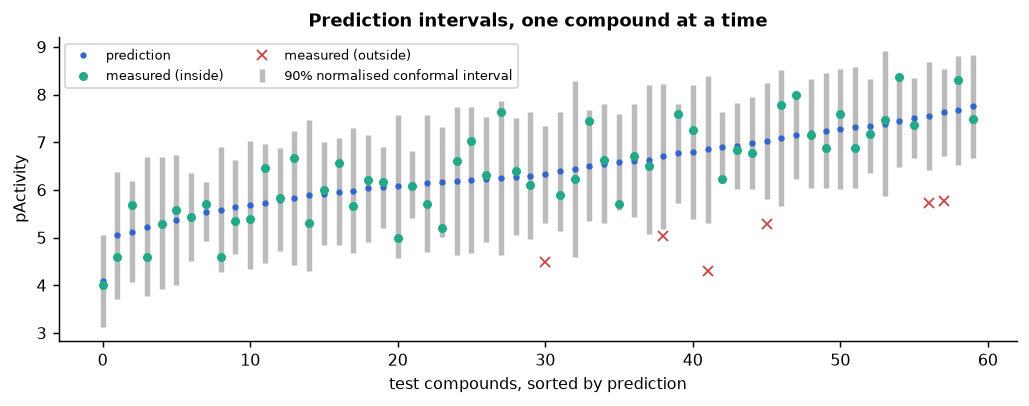

In [14]:
# Figure 4: 90% conformal intervals for 60 test compounds, sorted by prediction.
q90p = conformal_quantile(np.abs(y[CA] - m_rand.predict(Xfp[CA])), 0.10)
sd_ca0 = np.stack([t.predict(Xfp[CA]) for t in m_rand.estimators_]).std(0) + 0.3
q90nrm = conformal_quantile(np.abs(y[CA] - m_rand.predict(Xfp[CA])) / sd_ca0, 0.10)
sd_te0 = np.stack([t.predict(Xfp[TE]) for t in m_rand.estimators_]).std(0) + 0.3
sel = np.argsort(pred_te)[::max(len(TE)//60, 1)][:60]
order = sel[np.argsort(pred_te[sel])]
half_n = q90nrm * sd_te0[order]
miss = np.abs(y[TE][order] - pred_te[order]) > half_n
fig, ax = plt.subplots(figsize=(8.0, 3.2))
ax.errorbar(np.arange(len(order)), pred_te[order], yerr=half_n, fmt="none",
            ecolor="#bbb", elinewidth=3, capsize=0, label="90% normalised conformal interval")
ax.plot(np.arange(len(order)), pred_te[order], ".", color="#36c", ms=5, label="prediction")
ax.plot(np.arange(len(order))[~miss], y[TE][order][~miss], "o", color="#2a8", ms=4, label="measured (inside)")
ax.plot(np.arange(len(order))[miss], y[TE][order][miss], "x", color="#c44", ms=6, label="measured (outside)")
ax.set_xlabel("test compounds, sorted by prediction"); ax.set_ylabel("pActivity")
ax.set_title("Prediction intervals, one compound at a time"); ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
print(f"in this displayed subset of {len(order)} compounds, {int(miss.sum())} fall outside their "
      f"90% interval ({100*miss.mean():.1f}%); over the whole test set the figure is "
      f"{100*(1-np.mean(np.abs(y[TE]-pred_te) <= q90nrm*sd_te0)):.1f}%")
print(f"interval half-widths in the subset: {half_n.min():.2f} to {half_n.max():.2f} log units")

<p class="caption"><b>Figure 4.</b> Sixty test compounds sorted by predicted potency, with their 90 % difficulty-normalised conformal intervals (grey bars), the prediction (blue dot) and the measured value (green circle inside the interval, red cross outside). Interval width varies by more than a factor of two between compounds, and the misses are counted in the printed line.</p>

Both variants cover close to their nominal levels on this split, and they differ in *efficiency*: the normalised version produces intervals of the same average width but a wide interquartile range, because it gives narrow intervals to easy compounds and wide ones to hard ones. Validity is a property of the method; efficiency is what makes it useful<sup class="c"><a href="#r14">[14]</a></sup>. An interval that is always 2.4 log units wide is valid and almost useless for prioritisation; one that is 1.5 units wide for half the library and 3.5 for the rest tells a chemist which predictions to act on.

A single split is one realisation of a random experiment, and the guarantee is on average over calibration sets. The next cell therefore repeats the whole procedure with twenty different random calibration/test partitions.

In [15]:
# Validity is an average property: 20 independent calibration/test partitions.
rows = []
for seed in range(20):
    tr, ca, te = random_split(len(y), seed=seed)
    m = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=0).fit(Xfp[tr], y[tr])
    a = np.abs(y[ca] - m.predict(Xfp[ca])); pt = m.predict(Xfp[te])
    for L in (0.80, 0.90, 0.95):
        q = conformal_quantile(a, 1 - L)
        rows.append({"seed": seed, "level": L, "coverage": float(np.mean(np.abs(y[te] - pt) <= q))})
rep_cov = pd.DataFrame(rows).groupby("level").agg(
    mean_coverage=("coverage", "mean"), sd=("coverage", "std"),
    min=("coverage", "min"), max=("coverage", "max"))
print(rep_cov.round(4).to_string())
print(f"\nnominal levels are recovered on average to within "
      f"{np.abs(rep_cov['mean_coverage'] - rep_cov.index).max():.3f}; the spread across splits "
      f"(SD {rep_cov['sd'].min():.3f}-{rep_cov['sd'].max():.3f}) is the sampling noise of a "
      f"{len(TE)}-compound test set")

       mean_coverage      sd     min     max
level                                       
0.80          0.7928  0.0258  0.7523  0.8517
0.90          0.9016  0.0192  0.8752  0.9458
0.95          0.9491  0.0156  0.9241  0.9747

nominal levels are recovered on average to within 0.007; the spread across splits (SD 0.016-0.026) is the sampling noise of a 553-compound test set


 calibration size  mean coverage  SD of coverage  mean width  SD of width
               20          0.828           0.114       2.298        0.790
               50          0.870           0.058       2.444        0.485
              100          0.864           0.033       2.303        0.275
              200          0.868           0.022       2.342        0.191
              400          0.877           0.010       2.412        0.082
              553          0.873           0.000       2.399        0.000


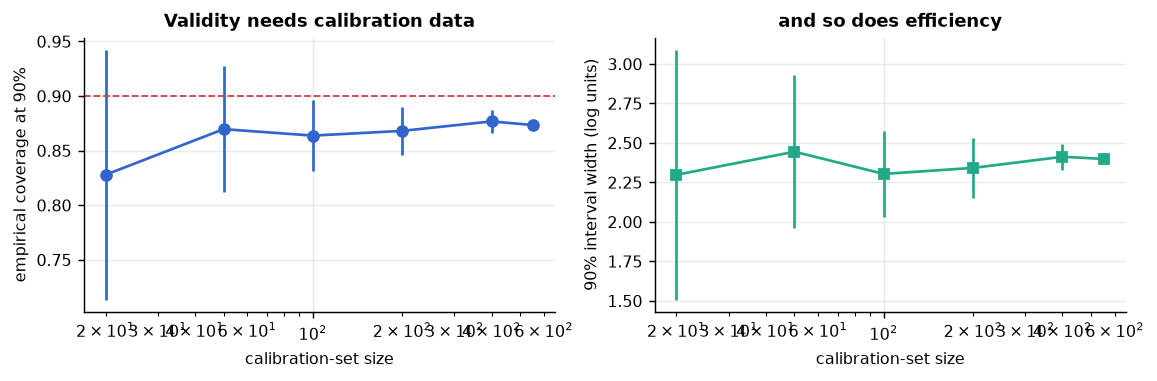

In [16]:
# Figure 6: how large must the calibration set be?
sizes = [20, 50, 100, 200, 400, len(CA)]
rows = []
for nc in sizes:
    covs, widths = [], []
    for seed in range(15):
        sub = np.random.default_rng(seed).choice(CA, nc, replace=False)
        a = np.abs(y[sub] - m_rand.predict(Xfp[sub]))
        q = conformal_quantile(a, 0.10)
        if q is None:
            continue
        covs.append(float(np.mean(np.abs(y[TE] - pred_te) <= q))); widths.append(2 * q)
    rows.append({"calibration size": nc, "mean coverage": np.mean(covs), "SD of coverage": np.std(covs),
                 "mean width": np.mean(widths), "SD of width": np.std(widths)})
csize = pd.DataFrame(rows)
print(csize.round(3).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.0))
axes[0].errorbar(csize["calibration size"], csize["mean coverage"], yerr=csize["SD of coverage"],
                 fmt="o-", color="#36c")
axes[0].axhline(0.90, color="#c44", ls="--", lw=1)
axes[0].set_xscale("log"); axes[0].set_xlabel("calibration-set size")
axes[0].set_ylabel("empirical coverage at 90%"); axes[0].set_title("Validity needs calibration data")
axes[1].errorbar(csize["calibration size"], csize["mean width"], yerr=csize["SD of width"],
                 fmt="s-", color="#2a8")
axes[1].set_xscale("log"); axes[1].set_xlabel("calibration-set size")
axes[1].set_ylabel("90% interval width (log units)"); axes[1].set_title("and so does efficiency")
for a in axes: a.grid(alpha=.25)
fig.tight_layout()

<p class="caption"><b>Figure 6.</b> Coverage (left) and width (right) of the 90 % conformal interval as the calibration set is subsampled, each point averaged over 15 draws with its standard deviation. With a few dozen calibration compounds the coverage is unbiased but wildly variable and the widths are erratic; stability arrives in the low hundreds. This is the practical reason to reserve a proper calibration split rather than reusing the test set.</p>

### 5.2 The coverage plot

normalised 90% widths: median 2.46, 10th pct 1.71, 90th pct 3.14; plain width 2.40 for every compound
coverage of the normalised predictor at 90%: 0.893


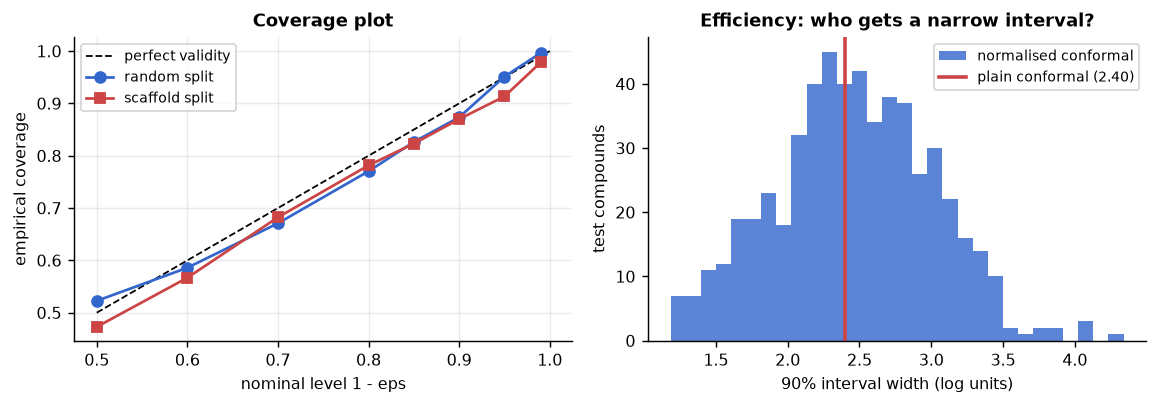

In [17]:
# Figure 5: coverage against nominal level, and the width distribution of the normalised predictor.
levels = np.array([0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.99])
cov_curve, cov_curve_s = [], []
alpha_r = np.abs(y[CA] - m_rand.predict(Xfp[CA]))
m_scaf = models["scaffold"]
alpha_s = np.abs(y[CAs] - m_scaf.predict(Xfp[CAs]))
pt_s = m_scaf.predict(Xfp[TEs])
for L in levels:
    q = conformal_quantile(alpha_r, 1 - L); cov_curve.append(np.mean(np.abs(y[TE] - pred_te) <= q))
    qs = conformal_quantile(alpha_s, 1 - L); cov_curve_s.append(np.mean(np.abs(y[TEs] - pt_s) <= qs))
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.2))
axes[0].plot([0.5, 1], [0.5, 1], "k--", lw=1, label="perfect validity")
axes[0].plot(levels, cov_curve, "o-", color="#36c", label="random split")
axes[0].plot(levels, cov_curve_s, "s-", color="#c44", label="scaffold split")
axes[0].set_xlabel("nominal level 1 - eps"); axes[0].set_ylabel("empirical coverage")
axes[0].set_title("Coverage plot"); axes[0].legend(fontsize=7.5); axes[0].grid(alpha=.25)
sd_ca = np.stack([t.predict(Xfp[CA]) for t in m_rand.estimators_]).std(0) + 0.3
q90n = conformal_quantile(np.abs(y[CA] - m_rand.predict(Xfp[CA])) / sd_ca, 0.10)
w_norm = 2 * q90n * (sd_trees + 0.3)
q90 = conformal_quantile(alpha_r, 0.10)
axes[1].hist(w_norm, bins=30, color="#36c", alpha=.8, label="normalised conformal")
axes[1].axvline(2 * q90, color="#c44", lw=2, label=f"plain conformal ({2*q90:.2f})")
axes[1].set_xlabel("90% interval width (log units)"); axes[1].set_ylabel("test compounds")
axes[1].set_title("Efficiency: who gets a narrow interval?"); axes[1].legend(fontsize=7.5)
fig.tight_layout()
print(f"normalised 90% widths: median {np.median(w_norm):.2f}, 10th pct {np.percentile(w_norm,10):.2f}, "
      f"90th pct {np.percentile(w_norm,90):.2f}; plain width {2*q90:.2f} for every compound")
print(f"coverage of the normalised predictor at 90%: "
      f"{np.mean(np.abs(y[TE]-pred_te) <= q90n*(sd_trees+0.3)):.3f}")

<p class="caption"><b>Figure 5.</b> Left: empirical coverage against nominal level for the conformal predictor under the random split (blue) and under the scaffold split (red); the diagonal is perfect validity. The random-split curve tracks the diagonal; the scaffold-split curve falls below it at high confidence, where the guarantee is needed most. Right: the distribution of 90 % interval widths from the difficulty-normalised predictor, against the single fixed width of the plain predictor (red line) — the same average coverage, distributed where the model is actually uncertain.</p>

## 6. When the guarantee breaks: exchangeability and the scaffold split

Conformal validity requires only that the calibration and test compounds be **exchangeable** — that their joint distribution not depend on which is labelled "calibration". A random split satisfies it by construction. A scaffold split does not: the test compounds belong to chemical families chosen to be absent from the other parts<sup class="c"><a href="#r16">[16]</a><a href="#r17">[17]</a></sup>. The practical question is how much coverage is lost, and the realistic deployment scenario is worse than the symmetric one — in practice a model is calibrated on whatever data is at hand (same chemotypes as the training set) and then applied to new chemistry.

In [18]:
# Three scenarios, same model family, same nominal levels.
pool = np.concatenate([TRs, CAs])
rp = np.random.default_rng(1).permutation(len(pool))
TRm, CAm = pool[rp[:int(0.75*len(pool))]], pool[rp[int(0.75*len(pool)):]]
m_mix = fit_rf(TRm)
scen = {
    "A. random split (exchangeable)": (m_rand, CA, TE),
    "B. scaffold split, calibration also on new scaffolds": (m_scaf, CAs, TEs),
    "C. calibrated in-domain, tested on new scaffolds": (m_mix, CAm, TEs),
}
rows = []
for name, (mm, ca, te) in scen.items():
    a = np.abs(y[ca] - mm.predict(Xfp[ca])); pt = mm.predict(Xfp[te])
    d_med = float(np.median(knn_distance(te, TRm if name.startswith("C") else (TRs if name.startswith("B") else TR))))
    r = {"scenario": name, "median kNN distance (test)": d_med,
         "RMSE": float(np.sqrt(((y[te] - pt) ** 2).mean()))}
    for L in (0.80, 0.90, 0.95):
        q = conformal_quantile(a, 1 - L)
        r[f"cov@{int(L*100)}"] = float(np.mean(np.abs(y[te] - pt) <= q))
        r[f"width@{int(L*100)}"] = 2 * q
    rows.append(r)
cover = pd.DataFrame(rows)
print(cover.round(3).to_string(index=False))
print("\ncoverage shortfall (empirical minus nominal):")
for _, r in cover.iterrows():
    print(f"  {r['scenario'][:46]:46s} "
          + "  ".join(f"{int(L*100)}%: {r[f'cov@{int(L*100)}'] - L:+.3f}" for L in (0.80, 0.90, 0.95)))

                                            scenario  median kNN distance (test)  RMSE  cov@80  width@80  cov@90  width@90  cov@95  width@95
                      A. random split (exchangeable)                       0.352 0.769   0.770     1.733   0.873     2.399   0.951     3.342
B. scaffold split, calibration also on new scaffolds                       0.511 0.927   0.782     2.253   0.870     2.833   0.913     3.313
    C. calibrated in-domain, tested on new scaffolds                       0.509 0.882   0.742     1.874   0.850     2.590   0.921     3.211

coverage shortfall (empirical minus nominal):
  A. random split (exchangeable)                 80%: -0.030  90%: -0.027  95%: +0.001
  B. scaffold split, calibration also on new sca 80%: -0.018  90%: -0.030  95%: -0.037
  C. calibrated in-domain, tested on new scaffol 80%: -0.058  90%: -0.050  95%: -0.029


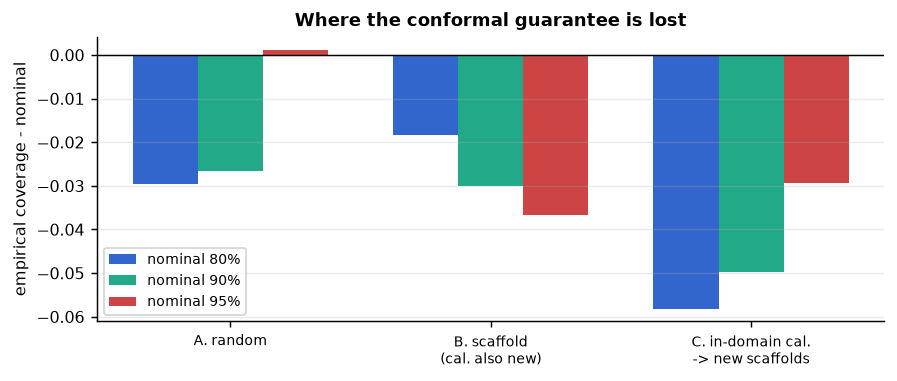

In [19]:
# Figure 7: coverage shortfall by scenario and nominal level.
fig, ax = plt.subplots(figsize=(7.0, 3.0))
w = 0.25
for k, L in enumerate([0.80, 0.90, 0.95]):
    ax.bar(np.arange(3) + (k - 1) * w, [cover.loc[i, f"cov@{int(L*100)}"] - L for i in range(3)],
           width=w, color=["#36c", "#2a8", "#c44"][k], label=f"nominal {int(L*100)}%")
ax.axhline(0, color="k", lw=.8)
ax.set_xticks(range(3))
ax.set_xticklabels(["A. random", "B. scaffold\n(cal. also new)",
                    "C. in-domain cal.\n-> new scaffolds"], fontsize=7.5)
ax.set_ylabel("empirical coverage - nominal"); ax.legend(fontsize=7.5)
ax.set_title("Where the conformal guarantee is lost"); ax.grid(alpha=.25, axis="y")
fig.tight_layout()

<p class="caption"><b>Figure 7.</b> Empirical coverage minus nominal level for the three scenarios at three confidence levels. Scenario A (random split, exchangeable) scatters around zero; both scaffold scenarios fall below it, and scenario C — calibrated on familiar chemistry and applied to new scaffolds — is short at every level while also producing narrower intervals than scenario B.</p>

Read the shortfalls, not the coverages. Under the random split the predictor is valid to within sampling noise. Under both scaffold scenarios the coverage at 95 % falls short — and in scenario C, the realistic one, the shortfall appears at every level, because the calibration residuals were collected on compounds the model finds easy and the test compounds are not like them. The intervals are also *narrower* in scenario C than in scenario B, which is the dangerous combination: confident and wrong.

Three consequences for practice:

1. **Calibrate on data that resembles the deployment population.** If the model will be applied to a new chemotype, the calibration set must contain new chemotypes — which is what scenario B does, and why its shortfall is smaller.
2. **Report coverage on a split that matches the claim**, exactly as for point performance (Unit 12). A conformal predictor validated only on a random split carries no guarantee for new chemistry; Norinder and co-workers' introduction of conformal prediction to QSAR<sup class="c"><a href="#r18">[18]</a></sup> and the applied studies that followed<sup class="c"><a href="#r19">[19]</a><a href="#r20">[20]</a><a href="#r21">[21]</a></sup> all make this the central practical caveat.
3. **Combine with the applicability domain.** The clean workflow is: compute the AD distance; refuse (or widen) predictions outside it; report conformal intervals for the rest, with coverage measured on a comparable split<sup class="c"><a href="#r22">[22]</a><a href="#r23">[23]</a></sup>.

## 7. Conformal classification: prediction sets instead of labels

For the potency-class problem (pActivity ≥ 7 or not) the same recipe produces a **prediction set** rather than a label. Using $\alpha = 1 - \hat p(\text{class})$ as the nonconformity score, a class is included in the set when its nonconformity does not exceed the calibration quantile. Four outcomes are possible: a singleton (confident), both classes (uninformative but honest), the empty set (the compound conforms to neither class — a flag for an outlier), and, for a singleton, the possibility of being wrong at the nominal rate.

The **Mondrian** (class-conditional) variant calibrates a separate quantile per class, which matters whenever the classes are imbalanced: plain conformal classification guarantees *marginal* coverage and can achieve it by covering the majority class very well and the minority class badly.

In [20]:
# Conformal classification: plain vs Mondrian, with set-size statistics.
from sklearn.ensemble import RandomForestClassifier
clf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=0).fit(Xfp[TR], ycls[TR])
Pca, Pte = clf.predict_proba(Xfp[CA]), clf.predict_proba(Xfp[TE])

def conformal_sets(eps, mondrian=True):
    inc = np.zeros((len(TE), 2), dtype=bool)
    for k in (0, 1):
        if mondrian:
            a = 1 - Pca[ycls[CA] == k, k]                     # calibrate within the class
        else:
            a = 1 - Pca[np.arange(len(CA)), ycls[CA]]         # one pooled quantile
        q = conformal_quantile(a, eps)
        inc[:, k] = (1 - Pte[:, k]) <= q
    return inc

rows = []
for eps in (0.20, 0.10, 0.05):
    for mondrian in (False, True):
        inc = conformal_sets(eps, mondrian)
        hit = inc[np.arange(len(TE)), ycls[TE]]
        rows.append({"1-eps": 1 - eps, "variant": "Mondrian" if mondrian else "plain",
                     "coverage": hit.mean(),
                     "coverage class 0": hit[ycls[TE] == 0].mean(),
                     "coverage class 1": hit[ycls[TE] == 1].mean(),
                     "singletons": (inc.sum(1) == 1).mean(),
                     "both classes": (inc.sum(1) == 2).mean(),
                     "empty": (inc.sum(1) == 0).mean()})
cc = pd.DataFrame(rows)
print(cc.round(3).to_string(index=False))
print(f"\nclass prevalence in the test set: {ycls[TE].mean():.3f} potent / {1-ycls[TE].mean():.3f} not")

 1-eps  variant  coverage  coverage class 0  coverage class 1  singletons  both classes  empty
  0.80    plain     0.808             0.879             0.640       0.978         0.000  0.022
  0.80 Mondrian     0.821             0.815             0.835       0.984         0.016  0.000
  0.90    plain     0.899             0.946             0.787       0.817         0.183  0.000
  0.90 Mondrian     0.895             0.884             0.921       0.778         0.222  0.000
  0.95    plain     0.955             0.974             0.909       0.646         0.354  0.000
  0.95 Mondrian     0.939             0.923             0.976       0.564         0.436  0.000

class prevalence in the test set: 0.297 potent / 0.703 not


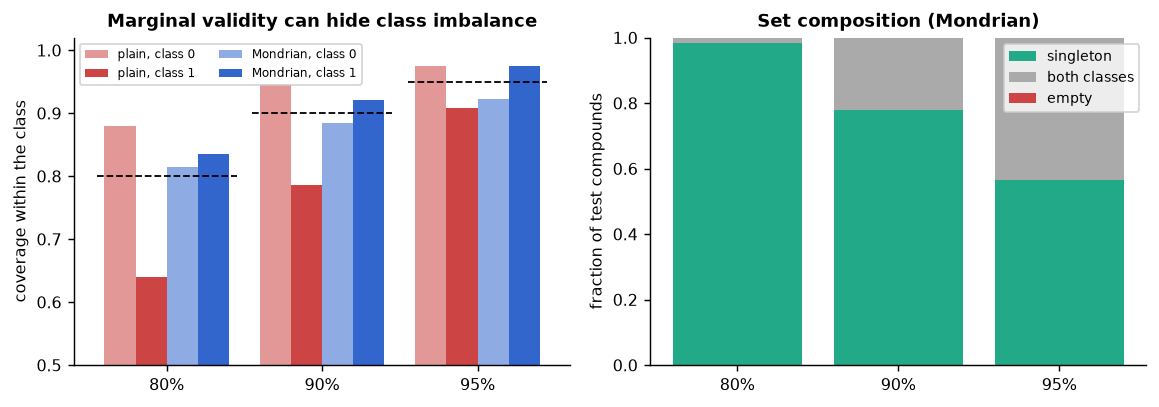

In [21]:
# Figure 8: class-conditional coverage and set composition, plain vs Mondrian.
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.2))
x = np.arange(3); w = 0.2
for k, (variant, colr) in enumerate([("plain", "#c44"), ("Mondrian", "#36c")]):
    s = cc[cc["variant"] == variant]
    axes[0].bar(x + (k - 0.5) * 2 * w - w/2, s["coverage class 0"], width=w, color=colr, alpha=.55,
                label=f"{variant}, class 0")
    axes[0].bar(x + (k - 0.5) * 2 * w + w/2, s["coverage class 1"], width=w, color=colr,
                label=f"{variant}, class 1")
for k, L in enumerate([0.80, 0.90, 0.95]):
    axes[0].hlines(L, k - 0.45, k + 0.45, color="k", ls="--", lw=1)
axes[0].set_xticks(x); axes[0].set_xticklabels(["80%", "90%", "95%"])
axes[0].set_ylim(0.5, 1.02); axes[0].set_ylabel("coverage within the class")
axes[0].set_title("Marginal validity can hide class imbalance"); axes[0].legend(fontsize=6.5, ncol=2)
mo = cc[cc["variant"] == "Mondrian"]
axes[1].bar(x, mo["singletons"], color="#2a8", label="singleton")
axes[1].bar(x, mo["both classes"], bottom=mo["singletons"], color="#aaa", label="both classes")
axes[1].bar(x, mo["empty"], bottom=mo["singletons"] + mo["both classes"], color="#c44", label="empty")
axes[1].set_xticks(x); axes[1].set_xticklabels(["80%", "90%", "95%"])
axes[1].set_ylabel("fraction of test compounds"); axes[1].set_title("Set composition (Mondrian)")
axes[1].legend(fontsize=7.5)
fig.tight_layout()

<p class="caption"><b>Figure 8.</b> Left: coverage within each class for the plain and Mondrian conformal classifiers at three confidence levels, with the nominal level marked. The plain variant achieves its marginal target by over-covering the majority class and under-covering the minority one; the Mondrian variant holds both classes near the nominal level. Right: composition of the Mondrian prediction sets — as confidence rises, the fraction of informative singletons falls and the fraction of "both classes" answers grows.</p>

The right-hand panel is the honest trade: a 95 % guarantee on a model with this discrimination can only be bought by refusing to decide for a large fraction of compounds. That is not a defect, it is information — it tells a project how many compounds can actually be triaged at the confidence it requires.

## 8. Probability calibration

A prediction set answers "which classes are plausible". A calibrated probability answers "how often is a compound with score 0.7 actually potent" — the quantity a decision needs when costs are asymmetric. Two standard recalibrations exist: **Platt scaling**, a logistic fit of the label on the score<sup class="c"><a href="#r27">[27]</a></sup>, and **isotonic regression**, a monotone step function<sup class="c"><a href="#r26">[26]</a></sup>, both fitted on the calibration set (never on the training or test data). Quality is read from a **reliability diagram** and summarised by the **Brier score**<sup class="c"><a href="#r29">[29]</a></sup>, the mean squared difference between probability and outcome, which decomposes into calibration and refinement terms<sup class="c"><a href="#r30">[30]</a></sup>.

In [22]:
# Platt and isotonic recalibration, with reliability statistics.
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import brier_score_loss, roc_auc_score
p_raw = Pte[:, 1]
p_platt = CalibratedClassifierCV(FrozenEstimator(clf), method="sigmoid") \
            .fit(Xfp[CA], ycls[CA]).predict_proba(Xfp[TE])[:, 1]
p_iso = CalibratedClassifierCV(FrozenEstimator(clf), method="isotonic") \
          .fit(Xfp[CA], ycls[CA]).predict_proba(Xfp[TE])[:, 1]
rows = []
for name, p in [("raw random forest", p_raw), ("Platt (sigmoid)", p_platt), ("isotonic", p_iso)]:
    frac, mean_p = calibration_curve(ycls[TE], p, n_bins=8, strategy="quantile")
    rows.append({"probabilities": name, "Brier": brier_score_loss(ycls[TE], p),
                 "ROC-AUC": roc_auc_score(ycls[TE], p), "mean predicted": p.mean(),
                 "observed prevalence": ycls[TE].mean(),
                 "calibration error (8 bins)": float(np.mean(np.abs(frac - mean_p)))})
cal = pd.DataFrame(rows)
print(cal.round(4).to_string(index=False))
print(f"\nBrier score of always predicting the prevalence "
      f"({ycls[TE].mean():.3f}): {brier_score_loss(ycls[TE], np.full(len(TE), ycls[TE].mean())):.4f}")

    probabilities  Brier  ROC-AUC  mean predicted  observed prevalence  calibration error (8 bins)
raw random forest 0.1242   0.8870          0.3194               0.2966                      0.0427
  Platt (sigmoid) 0.1245   0.8870          0.3282               0.2966                      0.0522
         isotonic 0.1231   0.8854          0.3234               0.2966                      0.0476

Brier score of always predicting the prevalence (0.297): 0.2086


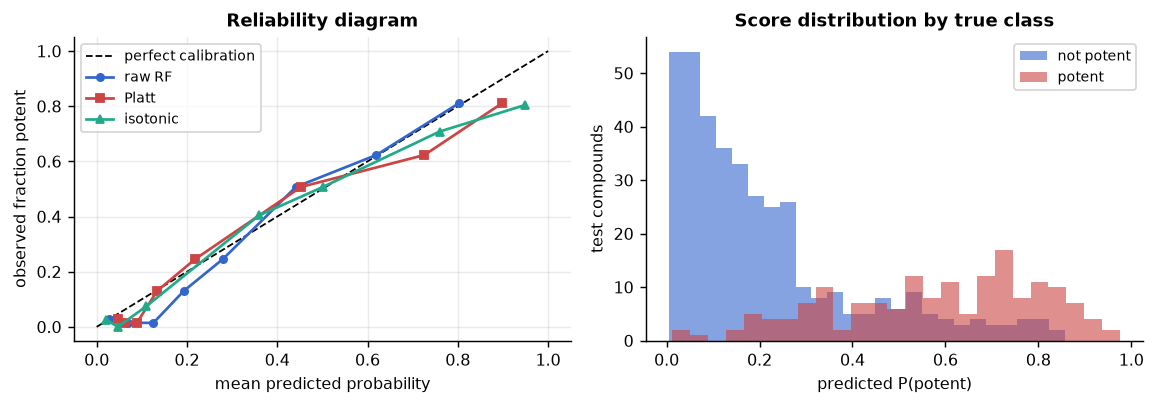

In [23]:
# Figure 9: reliability diagrams before and after recalibration, plus the score histogram.
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.2))
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
for name, p, colr, mk in [("raw RF", p_raw, "#36c", "o"), ("Platt", p_platt, "#c44", "s"),
                          ("isotonic", p_iso, "#2a8", "^")]:
    frac, mean_p = calibration_curve(ycls[TE], p, n_bins=8, strategy="quantile")
    axes[0].plot(mean_p, frac, mk + "-", ms=4, color=colr, label=name)
axes[0].set_xlabel("mean predicted probability"); axes[0].set_ylabel("observed fraction potent")
axes[0].set_title("Reliability diagram"); axes[0].legend(fontsize=7.5); axes[0].grid(alpha=.25)
axes[1].hist(p_raw[ycls[TE] == 0], bins=25, alpha=.6, color="#36c", label="not potent")
axes[1].hist(p_raw[ycls[TE] == 1], bins=25, alpha=.6, color="#c44", label="potent")
axes[1].set_xlabel("predicted P(potent)"); axes[1].set_ylabel("test compounds")
axes[1].set_title("Score distribution by true class"); axes[1].legend(fontsize=7.5)
fig.tight_layout()

<p class="caption"><b>Figure 9.</b> Left: reliability diagram with eight quantile bins — the raw forest probabilities already lie close to the diagonal, and neither Platt scaling nor isotonic regression improves the Brier score materially on this problem. Right: the distribution of raw scores by true class, which shows why: the forest's averaging over 300 trees produces scores that are neither saturated at 0/1 nor compressed around the prevalence.</p>

The negative result is worth keeping: **recalibration is not always needed, and you only know by measuring.** Random forests with many trees are often close to calibrated on balanced-ish problems, whereas boosted trees and neural networks are typically over-confident<sup class="c"><a href="#r28">[28]</a></sup>. The decision rule is simple: fit Platt and isotonic on the calibration set, compare Brier scores and reliability curves on the test set, and keep the raw probabilities if they win — as they roughly do here.

<div class="exercise"><h4>Exercise 2</h4>
<p>Replace the random forest with <code>lgb.LGBMClassifier(n_estimators=400)</code> and repeat the calibration comparison. Boosted trees are usually over-confident: report the Brier score and the calibration error before and after Platt scaling, and say which of the two recalibrations you would deploy and why.</p></div>

## 9. The OECD principles and a QMRF-style report

Regulatory and editorial expectations for a (Q)SAR model are codified in the five **OECD principles**: a model submitted for a regulatory purpose should have (1) a defined endpoint, (2) an unambiguous algorithm, (3) a defined domain of applicability, (4) appropriate measures of goodness-of-fit, robustness and predictivity, and (5) a mechanistic interpretation, if possible. The reporting vehicle is the **QSAR Model Reporting Format (QMRF)**, a structured document with sections matching those principles; Tropsha's best-practice paper<sup class="c"><a href="#r9">[9]</a></sup> and Tetko and co-workers' critical assessment<sup class="c"><a href="#r10">[10]</a></sup> are the practical commentaries a student should read alongside the guidance itself.

Everything the first four principles require has been computed in this notebook, so the report can be generated rather than written. Principle 5 is the one that cannot be automated — and <a href="../U16_Interpretability/index.html">Unit 16</a> is the unit about why a mechanistic interpretation needs its own controls.

<div class="box bridge"><h4>Bridge</h4>
<p>Regulatory QSAR vocabulary, descriptors and the ADMET context are developed in the cheminformatics course: <a href="../../Cheminformatics/U12_Classical_QSAR/index.html">U12 (classical QSAR)</a> and <a href="../../Cheminformatics/U14_Validation/index.html">U14 (validation)</a>, with the chemical-space view in <a href="../../Cheminformatics/U8_Chemical_Space/index.html">U8</a>. Protein-structure confidence scores — pLDDT and PAE, the structural analogue of everything in this unit — appear in the bioinformatics course, <a href="../../BGM324/02_Protein_Structure_Prediction/index.html">BGM324 unit 02</a>, and docking-score reliability in <a href="../../BGM324/03_Molecular_Docking/index.html">unit 03</a>. The probabilistic background is the artificial-intelligence course, <a href="../../BGM411/Python/S1_Model_Evaluation/index.html">BGM411 S1</a>. Inside this course: <a href="../U7_Estimation/index.html">Unit 7</a> for confidence intervals and the bootstrap, <a href="../U10_Bayesian/index.html">Unit 10</a> for the Bayesian route to the same question, and <a href="../U23_Communication/index.html">Unit 23</a> for reporting standards.</p></div>

In [24]:
# A QMRF-style report, generated from the quantities computed above.
q90_plain = conformal_quantile(alpha_r, 0.10)
report = f'''
QSAR MODEL REPORTING FORMAT (QMRF-style summary) - generated by this notebook
============================================================================
1. QSAR identifier
   Title            : Random-forest classifier/regressor of ROCK1 inhibitory potency
   Date / software  : scikit-learn {sklearn.__version__}, RDKit {rdkit.__version__}, seed 0

2. General information
   Endpoint         : pActivity = -log10(IC50/Ki/Kd in M) against human ROCK1 (ChEMBL CHEMBL3231)
   Data source      : ChEMBL release 37, curated table rock1_chembl_curated.csv (reference [34])
   Compounds        : {len(cmp_)} standardised parent structures with at least one exact measurement
   Target variable  : median of exact measurements per compound; censored records excluded
   Experimental unc.: pooled within-compound SD = {pooled_sd:.3f} log units ({len(rep)} replicated compounds)

3. Defined endpoint (OECD principle 1)
   Regression       : pActivity (continuous, {y.min():.2f} to {y.max():.2f})
   Classification   : potent if pActivity >= 7.0 (100 nM); prevalence {ycls.mean():.3f}

4. Unambiguous algorithm (principle 2)
   Descriptors      : Morgan fingerprint, radius 2, 2048 bits, from standardised SMILES
   Algorithm        : RandomForest (300 trees, min_samples_leaf = 2, random_state = 0)
   Splits           : random 60/20/20 and deterministic Bemis-Murcko scaffold 60/20/20

5. Applicability domain (principle 3)
   Definition       : mean Tanimoto distance to the 5 nearest training compounds < {thr_knn:.2f}
                      (threshold = 90th percentile of the calibration set)
   Coverage         : {100*np.mean(d_knn < thr_knn):.1f}% of random-split test compounds inside
   Evidence         : MAE {deg["MAE"].iloc[0]:.3f} (nearest quartile) -> {deg["MAE"].iloc[-1]:.3f} (farthest quartile);
                      errors > 1 log unit {deg["frac_error_gt_1"].iloc[0]:.1%} -> {deg["frac_error_gt_1"].iloc[-1]:.1%}
   Secondary        : descriptor bounding box ({100*in_box.mean():.1f}% inside, no degradation outside),
                      leverage h* = {h_star:.4f} for the descriptor ridge reference model

6. Goodness-of-fit, robustness and predictivity (principle 4)
   Random split     : R2 {info.loc[0,"R2"]:.3f}, MAE {info.loc[0,"MAE"]:.3f}, RMSE {info.loc[0,"RMSE"]:.3f} log units
   Scaffold split   : R2 {info.loc[1,"R2"]:.3f}, MAE {info.loc[1,"MAE"]:.3f}, RMSE {info.loc[1,"RMSE"]:.3f} log units
   Classification   : ROC-AUC {roc_auc_score(ycls[TE], p_raw):.3f}, Brier {brier_score_loss(ycls[TE], p_raw):.4f}
   Uncertainty      : inductive conformal, 90% interval width {2*q90_plain:.2f} log units,
                      empirical coverage {icp_plain.loc[1,"coverage"]:.3f} (random split),
                      {cover.loc[2,"cov@90"]:.3f} when calibrated in-domain and tested on new scaffolds
   Benchmark        : experimental floor RMSE >= {pooled_sd:.3f}; model/floor ratio {info.loc[0,"RMSE"]/pooled_sd:.2f}

7. Mechanistic interpretation (principle 5)
   Not established automatically. Fingerprint-bit attributions (Unit 16) are consistent with the
   known hinge-binding motif of ROCK inhibitors but are confounded with training-set frequency.

8. Limitations
   - Public data from heterogeneous assays; IC50, Ki and Kd pooled after standardisation.
   - 1,516 censored compounds excluded from the regression target.
   - Conformal guarantees hold under exchangeability; coverage degrades on new scaffolds (section 6).
'''
print(report)


QSAR MODEL REPORTING FORMAT (QMRF-style summary) - generated by this notebook
1. QSAR identifier
   Title            : Random-forest classifier/regressor of ROCK1 inhibitory potency
   Date / software  : scikit-learn 1.9.0, RDKit 2026.03.4, seed 0

2. General information
   Endpoint         : pActivity = -log10(IC50/Ki/Kd in M) against human ROCK1 (ChEMBL CHEMBL3231)
   Data source      : ChEMBL release 37, curated table rock1_chembl_curated.csv (reference [34])
   Compounds        : 2764 standardised parent structures with at least one exact measurement
   Target variable  : median of exact measurements per compound; censored records excluded
   Experimental unc.: pooled within-compound SD = 0.506 log units (375 replicated compounds)

3. Defined endpoint (OECD principle 1)
   Regression       : pActivity (continuous, 3.57 to 9.82)
   Classification   : potent if pActivity >= 7.0 (100 nM); prevalence 0.331

4. Unambiguous algorithm (principle 2)
   Descriptors      : Morgan fingerprin

In [25]:
# Everything this notebook measured, in one table.
final = pd.DataFrame([
    ("experimental floor (pooled replicate SD)", f"{pooled_sd:.3f} log units", "aleatoric; irreducible"),
    ("model RMSE, random split", f"{info.loc[0,'RMSE']:.3f}", f"{info.loc[0,'RMSE']/pooled_sd:.2f} x the floor"),
    ("model RMSE, scaffold split", f"{info.loc[1,'RMSE']:.3f}", f"{info.loc[1,'RMSE']/pooled_sd:.2f} x the floor"),
    ("AD: bounding box", f"{100*in_box.mean():.1f}% inside", "no degradation outside: useless here"),
    ("AD: leverage (ridge model)", f"{100*out_lev.mean():.1f}% outside h*",
     f"MAE {np.abs(res[~out_lev]).mean():.2f} -> {np.abs(res[out_lev]).mean():.2f}"),
    ("AD: kNN Tanimoto distance", f"median {np.median(d_knn):.3f}",
     f"MAE {deg['MAE'].iloc[0]:.2f} -> {deg['MAE'].iloc[-1]:.2f} across quartiles"),
    ("RF +-1.645 SD interval", f"coverage {cov_rf:.3f}", "nominal 0.90: under-covers"),
    ("quantile regression interval", f"coverage {cov_q:.3f}", "nominal 0.90: under-covers"),
    ("conformal, random split", f"coverage {icp_plain.loc[1,'coverage']:.3f}",
     f"width {icp_plain.loc[1,'mean width']:.2f} log units"),
    ("conformal, 20 repetitions", f"mean coverage {rep_cov.loc[0.90,'mean_coverage']:.3f}",
     f"SD across splits {rep_cov.loc[0.90,'sd']:.3f}"),
    ("conformal, in-domain calibration -> new scaffolds", f"coverage {cover.loc[2,'cov@90']:.3f}",
     "guarantee lost: exchangeability fails"),
    ("conformal classification (Mondrian, 90%)",
     f"singletons {cc[(cc['variant']=='Mondrian') & (cc['1-eps']==0.90)]['singletons'].iloc[0]:.2f}",
     "the price of a guarantee is abstention"),
    ("probability calibration", f"Brier raw {brier_score_loss(ycls[TE], p_raw):.4f}",
     f"Platt {brier_score_loss(ycls[TE], p_platt):.4f}, isotonic {brier_score_loss(ycls[TE], p_iso):.4f}"),
], columns=["quantity", "value", "reading"])
final

,quantity,value,reading
0,experimental floor (pooled replicate SD),0.506 log units,aleatoric; irreducible
1,"model RMSE, random split",0.769,1.52 x the floor
2,"model RMSE, scaffold split",0.927,1.83 x the floor
3,AD: bounding box,99.3% inside,no degradation outside: useless here
4,AD: leverage (ridge model),2.0% outside h*,MAE 0.79 -> 1.34
5,AD: kNN Tanimoto distance,median 0.352,MAE 0.50 -> 0.65 across quartiles
6,RF +-1.645 SD interval,coverage 0.857,nominal 0.90: under-covers
7,quantile regression interval,coverage 0.752,nominal 0.90: under-covers
8,"conformal, random split",coverage 0.873,width 2.40 log units
9,"conformal, 20 repetitions",mean coverage 0.902,SD across splits 0.019


<p class="caption"><b>Table 1.</b> Every uncertainty quantity computed in this notebook. Three rows are negative results — the bounding box does not work, and neither heuristic interval covers — and the last conformal row is the one to remember.</p>

## 10. Summary

**Two uncertainties, one floor.** Aleatoric uncertainty is noise in the measurement and cannot be modelled away; epistemic uncertainty is distance from what the model has seen and can be. The dataset's own replicates put the aleatoric floor at about half a log unit<sup class="c"><a href="#r2">[2]</a><a href="#r3">[3]</a></sup>, so a random-split RMSE of a small multiple of that is close to the best achievable, and every error analysis should be read against it.

**Applicability domain.** Four definitions were computed and judged by whether accuracy degrades outside them<sup class="c"><a href="#r4">[4]</a></sup>. The descriptor bounding box classified almost everything as inside and showed no degradation. Leverage with the $h^{*}=3p/n$ threshold and the Williams plot worked for the model it is defined for — the descriptor-space linear model<sup class="c"><a href="#r7">[7]</a></sup> — and says nothing about a fingerprint forest. Distance to the nearest training neighbours, computed in the model's own representation, was the one definition that tracked the error — modestly: in the retention experiment it ranked individual compounds no better than chance, while the model's own ensemble spread cut the RMSE of the retained half substantially. Density added little. The rule is to define the domain in the model's space, publish the degradation table, and use a model-internal difficulty estimate for per-compound triage.

**Intervals.** Ensemble spread and quantile regression both under-covered at a nominal 90 %. Inductive conformal prediction<sup class="c"><a href="#r11">[11]</a><a href="#r12">[12]</a><a href="#r13">[13]</a></sup> — three steps, a dozen lines, no distributional assumptions — reached its nominal coverage on a random split, on average over twenty repetitions, and the difficulty-normalised variant<sup class="c"><a href="#r15">[15]</a></sup> redistributed the same average width towards the compounds the model finds hard. Validity is guaranteed; efficiency is what you optimise.

**Where the guarantee goes.** Exchangeability is the only assumption, and a scaffold split violates it. Coverage fell short of nominal under both scaffold scenarios and most dangerously in the realistic one — calibrated on familiar chemistry, applied to new chemotypes — where the intervals were simultaneously narrower and less reliable<sup class="c"><a href="#r16">[16]</a><a href="#r17">[17]</a></sup>. Report coverage on a split that matches your claim.

**Sets and probabilities.** Conformal classification returns prediction sets whose composition makes the cost of confidence explicit: at 95 % a large fraction of compounds receive the uninformative "either class" answer. The Mondrian variant restores per-class validity that the marginal guarantee hides. Probability recalibration (Platt, isotonic) is cheap, must be fitted on a held-out calibration set, and on this random forest was not needed — a conclusion that required measuring the Brier score and the reliability curve<sup class="c"><a href="#r29">[29]</a><a href="#r30">[30]</a></sup>.

**Reporting.** The five OECD principles map one-to-one onto the sections of this notebook, and the QMRF-style report was generated from the computed quantities, with the limitations section carrying the censored compounds, the assay heterogeneity and the coverage loss on new scaffolds. <a href="../U18_Deep_Learning/index.html">Unit 18</a> asks what deep learning adds to the same problem, and <a href="../U20_MD_Analytics/index.html">Unit 20</a> applies the same statistical honesty to simulation output.

## 11. Self-assessment

<details><summary>1. Separate the two uncertainties for a concrete case: a model predicts pActivity 7.2 for a compound from a chemotype absent from the training set, measured once in a single laboratory.</summary>
<p>Aleatoric: the single measurement carries the assay's own error, about half a log unit for public data of this kind, which no model can remove. Epistemic: the compound is far from the training set in fingerprint space, so the model is extrapolating and its error is likely larger than its average test error. The first is reported as a floor; the second is detected by the applicability domain and absorbed into a wider conformal interval.</p></details>

<details><summary>2. Why is a descriptor bounding box a poor applicability domain for a fingerprint model?</summary>
<p>Because it is measured in a space the model does not use, and because it is a union of one-dimensional constraints: a molecule can satisfy all eleven descriptor ranges and still occupy a region of chemical space with no training compounds in it. In Section 3 it declared about 99 % of test compounds inside and the few outside were not predicted worse.</p></details>

<details><summary>3. What is h*, and what does a point in the top-right corner of a Williams plot mean?</summary>
<p>h* = 3p/n is the conventional leverage threshold for a linear model with p parameters and n training rows; leverage is the diagonal of the hat matrix, measuring distance from the centre of the training data in the model's metric. Top-right means high leverage and a large standardised residual: an influential compound that the model also predicts badly — the case that most deserves inspection before publication.</p></details>

<details><summary>4. Write down the conformal quantile index and explain the +1.</summary>
<p>k = ceil((n+1)(1-eps)) with n the calibration size. The +1 accounts for the test compound itself: validity comes from the rank of its nonconformity score among the n+1 scores being uniform under exchangeability. It also implies n >= 1/eps - 1, so 95 % confidence is impossible with fewer than 19 calibration points.</p></details>

<details><summary>5. A referee says "conformal prediction is distribution-free, so it needs no validation". Answer.</summary>
<p>It is free of assumptions about the data distribution and about the model, but not of the exchangeability assumption between calibration and test data. Section 6 showed coverage falling below nominal under a scaffold split — the deployment scenario a QSAR paper usually claims — so empirical coverage must be reported on the split that matches the claim, exactly like a point performance metric.</p></details>

<details><summary>6. Distinguish validity from efficiency, and give the numbers from this notebook.</summary>
<p>Validity is whether the empirical coverage reaches the nominal level; efficiency is how narrow the intervals are. The plain predictor gave every compound the same 90 % width of about 2.4 log units; the difficulty-normalised predictor kept comparable average coverage while varying widths by roughly a factor of two between easy and hard compounds.</p></details>

<details><summary>7. Why do the ensemble-spread intervals under-cover even though the spread correlates with the error?</summary>
<p>Because the spread measures disagreement among trees trained on the same data — a lower bound on the error that ignores the shared bias and the aleatoric noise. The correlation (positive, moderate) means it ranks difficulty well, which is why it makes a good <em>normaliser</em> inside a conformal predictor: conformal supplies the scale, the ensemble supplies the ranking.</p></details>

<details><summary>8. When does a conformal classifier return an empty set, and what should you do with that compound?</summary>
<p>When the predicted probability of every class is below the calibration threshold — the compound conforms to no class. It is a flag, not an answer: treat it as outside the applicability domain and either widen the analysis (more data of that kind) or decline to predict.</p></details>

<details><summary>9. What does Mondrian conformal prediction fix?</summary>
<p>Class-conditional validity. The plain version guarantees only marginal coverage and can reach it by covering the majority class far better than the minority: in Section 7 the plain variant's class-1 coverage fell well below nominal at the same time as its class-0 coverage exceeded it. Mondrian calibrates one quantile per class, keeping both near the target.</p></details>

<details><summary>10. Your random forest's Brier score does not improve after Platt scaling. What do you report?</summary>
<p>That the raw probabilities were already close to calibrated, with the reliability diagram and the Brier scores of all three variants as evidence, and that the raw model is therefore deployed. Recalibration is a hypothesis to test on held-out data, not a mandatory step; boosted trees and neural networks usually need it, forests with many trees often do not.</p></details>

<details><summary>11. Map the five OECD principles onto the sections of this notebook.</summary>
<p>(1) Defined endpoint: the pActivity definition and the 7.0 class boundary of Section 0; (2) unambiguous algorithm: the fingerprint and forest specification; (3) applicability domain: Section 3, with the degradation table as evidence; (4) goodness-of-fit, robustness and predictivity: the two splits, the conformal coverage and the experimental floor comparison; (5) mechanistic interpretation: Unit 16, with its own controls — and it is the only principle that cannot be generated automatically.</p></details>

<details><summary>12. A colleague asks for the single most useful uncertainty number for prioritising 10,000 catalogue compounds. What do you give?</summary>
<p>Per-compound: the distance to the training set (to decide who is in the domain at all) and a difficulty-normalised conformal interval at the confidence the project needs. Aggregate: the empirical coverage of that predictor measured on a split that resembles the catalogue — a scaffold or cluster split, not a random one — so that the number of compounds expected to be mis-prioritised can be stated in advance.</p></details>

## Glossary

<dl class="gloss">
<dt>Aleatoric uncertainty</dt><dd>Irreducible noise in the data-generating process, including measurement error; unaffected by more data.</dd>
<dt>Applicability domain (AD)</dt><dd>The region of chemical/feature space in which a model's predictions are considered reliable, with a stated definition and evidence of degradation outside it.</dd>
<dt>Brier score</dt><dd>Mean squared difference between predicted probability and binary outcome; lower is better, decomposable into calibration and refinement.</dd>
<dt>Calibration set</dt><dd>Data held out from training and from testing, used to fit the uncertainty (conformal quantiles, Platt/isotonic maps).</dd>
<dt>Conformal prediction (inductive)</dt><dd>Distribution-free framework producing intervals or prediction sets with guaranteed marginal coverage under exchangeability, using nonconformity scores from a calibration set.</dd>
<dt>Coverage</dt><dd>Fraction of test cases whose true value lies inside the predicted interval or set; compared with the nominal level 1 - eps.</dd>
<dt>Efficiency</dt><dd>Narrowness of valid intervals or smallness of valid prediction sets.</dd>
<dt>Epistemic uncertainty</dt><dd>Uncertainty from the model's ignorance (extrapolation, limited data); reducible with relevant additional data.</dd>
<dt>Exchangeability</dt><dd>Invariance of a joint distribution to permutation of the observations; the only assumption behind conformal validity.</dd>
<dt>Isotonic regression (calibration)</dt><dd>Monotone step-function recalibration of scores to probabilities; flexible but data-hungry.</dd>
<dt>Leverage / h*</dt><dd>Diagonal of the hat matrix measuring a point's distance from the training centroid in a linear model's metric; the 3p/n threshold marks structural outliers.</dd>
<dt>Mondrian conformal prediction</dt><dd>Class-conditional (or group-conditional) calibration, giving per-class rather than only marginal validity.</dd>
<dt>Nonconformity score</dt><dd>A measure of how unusual a (feature, label) pair is for the fitted model, e.g. the absolute residual or 1 - predicted class probability.</dd>
<dt>Platt scaling</dt><dd>Logistic recalibration of a score to a probability, fitted on held-out data.</dd>
<dt>Prediction set</dt><dd>The set of labels a conformal classifier cannot exclude at the chosen confidence; may be a singleton, several classes or empty.</dd>
<dt>QMRF</dt><dd>QSAR Model Reporting Format: the structured report whose sections follow the five OECD validation principles.</dd>
<dt>Reliability diagram</dt><dd>Observed event frequency against mean predicted probability per bin; the diagonal is perfect calibration.</dd>
<dt>Williams plot</dt><dd>Standardised residual against leverage, with h* and ±3 reference lines; the classical QSAR outlier diagnostic.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Hullermeier E, Waegeman W. Aleatoric and epistemic uncertainty in machine learning: an introduction to concepts and methods. <em>Mach Learn</em>. 2021;110:457-506. <a href="https://doi.org/10.1007/s10994-021-05946-3">doi:10.1007/s10994-021-05946-3</a></li>
<li id="r2">Kramer C, Kalliokoski T, Gedeck P, Vulpetti A. The experimental uncertainty of heterogeneous public Ki data. <em>J Med Chem</em>. 2012;55(11):5165-5173. <a href="https://doi.org/10.1021/jm300131x">doi:10.1021/jm300131x</a></li>
<li id="r3">Kalliokoski T, Kramer C, Vulpetti A, Gedeck P. Comparability of mixed IC50 data - a statistical analysis. <em>PLoS ONE</em>. 2013;8(4):e61007. <a href="https://doi.org/10.1371/journal.pone.0061007">doi:10.1371/journal.pone.0061007</a></li>
<li id="r4">Sahigara F, Mansouri K, Ballabio D, Mauri A, Consonni V, Todeschini R. Comparison of different approaches to define the applicability domain of QSAR models. <em>Molecules</em>. 2012;17(5):4791-4810. <a href="https://doi.org/10.3390/molecules17054791">doi:10.3390/molecules17054791</a></li>
<li id="r5">Netzeva TI, Worth AP, Aldenberg T, et al. Current status of methods for defining the applicability domain of (quantitative) structure-activity relationships. <em>Altern Lab Anim</em>. 2005;33(2):155-173. <a href="https://doi.org/10.1177/026119290503300209">doi:10.1177/026119290503300209</a></li>
<li id="r6">Jaworska J, Nikolova-Jeliazkova N, Aldenberg T. QSAR applicability domain estimation by projection of the training set in descriptor space: a review. <em>Altern Lab Anim</em>. 2005;33(5):445-459. <a href="https://doi.org/10.1177/026119290503300508">doi:10.1177/026119290503300508</a></li>
<li id="r7">Gramatica P. Principles of QSAR models validation: internal and external. <em>QSAR Comb Sci</em>. 2007;26(5):694-701. <a href="https://doi.org/10.1002/qsar.200610151">doi:10.1002/qsar.200610151</a></li>
<li id="r8">Roy K, Kar S, Ambure P. On a simple approach for determining applicability domain of QSAR models. <em>Chemom Intell Lab Syst</em>. 2015;145:22-29. <a href="https://doi.org/10.1016/j.chemolab.2015.04.013">doi:10.1016/j.chemolab.2015.04.013</a></li>
<li id="r9">Tropsha A. Best practices for QSAR model development, validation, and exploitation. <em>Mol Inform</em>. 2010;29(6-7):476-488. <a href="https://doi.org/10.1002/minf.201000061">doi:10.1002/minf.201000061</a></li>
<li id="r10">Tetko IV, Sushko I, Pandey AK, et al. Critical assessment of QSAR models of environmental toxicity against Tetrahymena pyriformis: focusing on applicability domain and overfitting by variable selection. <em>J Chem Inf Model</em>. 2008;48(9):1733-1746. <a href="https://doi.org/10.1021/ci800151m">doi:10.1021/ci800151m</a></li>
<li id="r11">Vovk V, Gammerman A, Shafer G. <em>Algorithmic Learning in a Random World</em>. Springer; 2005. <a href="https://doi.org/10.1007/b106715">doi:10.1007/b106715</a></li>
<li id="r12">Papadopoulos H, Proedrou K, Vovk V, Gammerman A. Inductive confidence machines for regression. In: <em>ECML 2002</em>. LNCS 2430. Springer; 2002:345-356. <a href="https://doi.org/10.1007/3-540-36755-1_29">doi:10.1007/3-540-36755-1_29</a></li>
<li id="r13">Lei J, G'Sell M, Rinaldo A, Tibshirani RJ, Wasserman L. Distribution-free predictive inference for regression. <em>J Am Stat Assoc</em>. 2018;113(523):1094-1111. <a href="https://doi.org/10.1080/01621459.2017.1307116">doi:10.1080/01621459.2017.1307116</a></li>
<li id="r14">Angelopoulos AN, Bates S. Conformal prediction: a gentle introduction. <em>Found Trends Mach Learn</em>. 2023;16(4):494-591. <a href="https://doi.org/10.1561/2200000101">doi:10.1561/2200000101</a></li>
<li id="r15">Romano Y, Patterson E, Candes EJ. Conformalized quantile regression. In: <em>NeurIPS 32</em>; 2019. <a href="https://doi.org/10.48550/arXiv.1905.03222">doi:10.48550/arXiv.1905.03222</a></li>
<li id="r16">Tibshirani RJ, Barber RF, Candes EJ, Ramdas A. Conformal prediction under covariate shift. In: <em>NeurIPS 32</em>; 2019. <a href="https://doi.org/10.48550/arXiv.1904.06019">doi:10.48550/arXiv.1904.06019</a></li>
<li id="r17">Barber RF, Candes EJ, Ramdas A, Tibshirani RJ. Conformal prediction beyond exchangeability. <em>Ann Stat</em>. 2023;51(2):816-845. <a href="https://doi.org/10.1214/23-AOS2276">doi:10.1214/23-AOS2276</a></li>
<li id="r18">Norinder U, Carlsson L, Boyer S, Eklund M. Introducing conformal prediction in predictive modeling: a transparent and flexible alternative to applicability domain determination. <em>J Chem Inf Model</em>. 2014;54(6):1596-1603. <a href="https://doi.org/10.1021/ci5001168">doi:10.1021/ci5001168</a></li>
<li id="r19">Svensson F, Aniceto N, Norinder U, et al. Conformal regression for quantitative structure-activity relationship modeling - quantifying prediction uncertainty. <em>J Chem Inf Model</em>. 2018;58(5):1132-1140. <a href="https://doi.org/10.1021/acs.jcim.8b00054">doi:10.1021/acs.jcim.8b00054</a></li>
<li id="r20">Alvarsson J, McShane SA, Norinder U, Spjuth O. Predicting with confidence: using conformal prediction in drug discovery. <em>J Pharm Sci</em>. 2021;110(1):42-49. <a href="https://doi.org/10.1016/j.xphs.2020.09.055">doi:10.1016/j.xphs.2020.09.055</a></li>
<li id="r21">Cortes-Ciriano I, Bender A. Deep confidence: a computationally efficient framework for calculating reliable prediction errors for deep neural networks. <em>J Chem Inf Model</em>. 2019;59(3):1269-1281. <a href="https://doi.org/10.1021/acs.jcim.8b00542">doi:10.1021/acs.jcim.8b00542</a></li>
<li id="r22">Mervin LH, Johansson S, Semenova E, Giblin KA, Engkvist O. Uncertainty quantification in drug design. <em>Drug Discov Today</em>. 2021;26(2):474-489. <a href="https://doi.org/10.1016/j.drudis.2020.11.027">doi:10.1016/j.drudis.2020.11.027</a></li>
<li id="r23">Hirschfeld L, Swanson K, Yang K, Barzilay R, Coley CW. Uncertainty quantification using neural networks for molecular property prediction. <em>J Chem Inf Model</em>. 2020;60(8):3770-3780. <a href="https://doi.org/10.1021/acs.jcim.0c00502">doi:10.1021/acs.jcim.0c00502</a></li>
<li id="r24">Koenker R, Bassett G. Regression quantiles. <em>Econometrica</em>. 1978;46(1):33-50. <a href="https://doi.org/10.2307/1913643">doi:10.2307/1913643</a></li>
<li id="r25">Lakshminarayanan B, Pritzel A, Blundell C. Simple and scalable predictive uncertainty estimation using deep ensembles. In: <em>NeurIPS 30</em>; 2017. <a href="https://doi.org/10.48550/arXiv.1612.01474">doi:10.48550/arXiv.1612.01474</a></li>
<li id="r26">Zadrozny B, Elkan C. Transforming classifier scores into accurate multiclass probability estimates. In: <em>Proc. 8th ACM SIGKDD</em>; 2002:694-699. <a href="https://doi.org/10.1145/775047.775151">doi:10.1145/775047.775151</a></li>
<li id="r27">Niculescu-Mizil A, Caruana R. Predicting good probabilities with supervised learning. In: <em>Proc. 22nd Int. Conf. on Machine Learning</em>; 2005:625-632. <a href="https://doi.org/10.1145/1102351.1102430">doi:10.1145/1102351.1102430</a></li>
<li id="r28">Guo C, Pleiss G, Sun Y, Weinberger KQ. On calibration of modern neural networks. <em>arXiv</em>. 2017:1706.04599. <a href="https://doi.org/10.48550/arXiv.1706.04599">doi:10.48550/arXiv.1706.04599</a></li>
<li id="r29">Brier GW. Verification of forecasts expressed in terms of probability. <em>Mon Weather Rev</em>. 1950;78(1):1-3. <a href="https://doi.org/10.1175/1520-0493(1950)078%3C0001:VOFEIT%3E2.0.CO;2">doi:10.1175/1520-0493(1950)078&lt;0001:VOFEIT&gt;2.0.CO;2</a></li>
<li id="r30">Van Calster B, McLernon DJ, van Smeden M, Wynants L, Steyerberg EW. Calibration: the Achilles heel of predictive analytics. <em>BMC Med</em>. 2019;17:230. <a href="https://doi.org/10.1186/s12916-019-1466-7">doi:10.1186/s12916-019-1466-7</a></li>
<li id="r31">Sheridan RP. Time-split cross-validation as a method for estimating the goodness of prospective prediction. <em>J Chem Inf Model</em>. 2013;53(4):783-790. <a href="https://doi.org/10.1021/ci400084k">doi:10.1021/ci400084k</a></li>
<li id="r32">Wallach I, Heifets A. Most ligand-based classification benchmarks reward memorization rather than generalization. <em>J Chem Inf Model</em>. 2018;58(5):916-932. <a href="https://doi.org/10.1021/acs.jcim.7b00403">doi:10.1021/acs.jcim.7b00403</a></li>
<li id="r33">Bemis GW, Murcko MA. The properties of known drugs. 1. Molecular frameworks. <em>J Med Chem</em>. 1996;39(15):2887-2893. <a href="https://doi.org/10.1021/jm9602928">doi:10.1021/jm9602928</a></li>
<li id="r34">Zdrazil B, Felix E, Hunter F, et al. The ChEMBL Database in 2023. <em>Nucleic Acids Res</em>. 2024;52(D1):D1180-D1192. <a href="https://doi.org/10.1093/nar/gkad1004">doi:10.1093/nar/gkad1004</a></li>
<li id="r35">Breiman L. Random forests. <em>Mach Learn</em>. 2001;45:5-32. <a href="https://doi.org/10.1023/A:1010933404324">doi:10.1023/A:1010933404324</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Vovk V, Gammerman A, Shafer G. <em>Algorithmic Learning in a Random World</em>. 2nd ed. Springer; 2022. - The source text for conformal prediction, including the validity proofs sketched here.</li>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning</em>. 2nd ed. Springer; 2009. - Chapter 7 for the bias-variance view of prediction error, Chapter 3 for leverage and the hat matrix.</li>
<li>Steyerberg EW. <em>Clinical Prediction Models</em>. 2nd ed. Springer; 2019. - Calibration and decision curves in the clinical setting.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>OECD. <em>Guidance Document on the Validation of (Quantitative) Structure-Activity Relationship [(Q)SAR] Models</em>. ENV/JM/MONO(2007)2, 2007, and the QMRF template of the European Commission's JRC: <a href="https://www.oecd.org/chemicalsafety/risk-assessment/validationofqsarmodels.htm">oecd.org - validation of QSAR models</a>.</li>
<li>Awesome Conformal Prediction, a curated list of tutorials and libraries (MAPIE, crepes, nonconformist): <a href="https://github.com/valeman/awesome-conformal-prediction">github.com/valeman/awesome-conformal-prediction</a>.</li>
<li>scikit-learn user guide, "Probability calibration": <a href="https://scikit-learn.org/stable/modules/calibration.html">scikit-learn.org/stable/modules/calibration.html</a>.</li>
<li>MAPIE documentation - a production implementation of the conformal methods written by hand here: <a href="https://mapie.readthedocs.io/">mapie.readthedocs.io</a>.</li>
</ul>